# GNSS Spoofing Detection by AoA Comparison

This notebook follows the paper flow for **GNSS Spoofing Detection by Estimating Angle of Arrival based on Carrier Phase Double Difference Measurements**.

The current experiment uses the full-spoof closed-room recordings captured on 2026-08-10. It computes fractional carrier-phase double differences and an anchored baseline-relative DD-method AoA for GPS L1 PRNs 4, 6, 7, 9, 11, 17, 19, 20, and 21. Because the capture is fully spoofed, Receiver 1 `NAV-SAT` is used only to anchor the AoA visualization; it is not independent ephemeris ground truth.


## Paper Algorithm Summary

1. Read carrier-phase measurements and navigation messages from two receivers.
2. Synchronize receiver RAWX epochs by receiver time of week.
3. Build author-aligned carrier phase: `RXM-RAWX.cpMes + NAV-PVT.nano * 1e-9 * RXM-RAWX.doMes`.
4. Compute receiver single differences.
5. Select a reference satellite and compute satellite double differences.
6. Apply the paper rounding operation to obtain fractional double differences.
7. Convert DD values to DD-method AoA using the reference-angle anchor.
8. Compare DD-method AoA with ephemeris-based AoA from NAV-SAT azimuth/elevation.
9. For partial spoofing, test whether the spoof PRNs converge to a common DD-method AoA while remaining distinct in ephemeris-based AoA.
10. Check `svUsed` over the full NAV-SAT timeline, not only the selected AoA window.


## Paper-to-Code Mapping

| Implementation artifact | Paper meaning |
| --- | --- |
| `carrier_phase_cycles` | Author-aligned carrier phase observable from Eq. 8 |
| `single_difference_cycles` | Receiver single difference from Eq. 9 |
| `double_difference_cycles` | Satellite double difference from Eq. 14 |
| `rounded_dd_cycles` | Integer round operation used in Eq. 17 and Eq. 18 |
| `fractional_dd_cycles` | Fractional DD after subtracting rounded DD, Eq. 18 |
| `candidate_aoa_deg` | Eq. 21 branch candidates for `m in {-2, -1, 0, 1, 2}` |
| `selected_aoa_deg` | Dynamic-programming selected DD-method AoA path from Algorithm 1 |
| `ephemeris_aoa_*_deg` | Baseline-relative AoA derived from receiver NAV-SAT azimuth/elevation |
| `sv_used_*` | Receiver NAV-SAT `svUsed` timeline over all NAV-SAT epochs |


In [1]:
from pathlib import Path
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import aoa_pipeline
importlib.reload(aoa_pipeline)

from aoa_pipeline import (
    aggregate_pairwise_geometry_residuals,
    classify_pairwise_geometry,
    compute_collapse_metrics,
    compute_pairwise_geometry_residuals,
    DatasetConfig,
    plot_aoa_method_comparison,
    plot_aoa_tracks,
    plot_candidate_cloud,
    plot_double_difference,
    plot_fractional_dd,
    plot_sv_used_timeline,
    plot_valid_m_candidates,
    run_paper_scenario,
    wrap_cycles,
)

pd.set_option("display.max_columns", 80)


## Scenario Configuration

This notebook is configured for `/Users/betty/Downloads/COM3___9600_260810_041055.ubx` and `/Users/betty/Downloads/COM4___9600_260810_041044.ubx`, recorded in a closed room under full spoofing. `RUN_FULL = True` processes the complete overlapping capture.

The experiment fixes PRN 6 as the DD reference and uses one scalar angle for the complete capture: `FIXED_REFERENCE_ALPHA_DEG = 82.00490527298308`. This is the median Receiver 1 `NAV-SAT` baseline-relative angle for PRN 6, used here as a **hypothetical valid reference** to reproduce the paper setup. It has not been independently surveyed, so replace it with a known reference angle before interpreting the absolute bearing. Changing this scalar moves the reconstructed angle level but does not create fractional-DD collapse.

For carrier-phase DD, the notebook now accepts a RAWX phase sample only when both `cpValid=1` and `halfCyc=1`. The earlier secondary bands near 111 degrees were caused by unresolved half-cycle samples (`halfCyc=0`), not by a time-varying reference angle.


In [2]:
RUN_FULL = True
DEFAULT_LENGTH = None if RUN_FULL else 500
OUTPUT_ROOT = Path("outputs/aoa_paper")

PARTIAL_SPOOF_ENABLED = False
SPOOF_SVIDS = (10, 23, 24, 25)
HARDCODED_REFERENCE_SVID = 16  # Most stable common receiver reference in the probe run.
# Fixed for the complete experiment, as assumed by the paper. Replace with a surveyed value.
FIXED_REFERENCE_ALPHA_DEG = 66.6
EXCLUDED_ANALYSIS_SVIDS = ()
CONVERGENCE_THRESHOLD_DEG = 5.0
SCORE_THRESHOLD = 0.5

# Single-difference receiver order = baseline polarity. "rx1-rx2" (default) or "rx2-rx1".
# The two give supplementary AoA (alpha vs 180-alpha); pick the one that makes DD-method AoA
# agree with the ephemeris-based AoA for this rig (i.e. matching which antenna is the north
# end of the baseline). Equivalent alternative: keep "rx1-rx2" and set navsat_azimuth_bias_deg=180.
SINGLE_DIFFERENCE_ORDER = "rx2-rx1"

SCENARIO_CONFIG = DatasetConfig(
    name="sp-partial-28-08-v4",
    receiver1_path=Path("/Users/betty/Developer/research/angle/dataset/sp-partial-28-08/v4/COM3___9600_260828_111540.ubx"),
    receiver2_path=Path("/Users/betty/Developer/research/angle/dataset/sp-partial-28-08/v4/COM4___9600_260828_111534.ubx"),
    alpha_r_deg=FIXED_REFERENCE_ALPHA_DEG,
    reference_svid=HARDCODED_REFERENCE_SVID,
    selected_svids=SPOOF_SVIDS if PARTIAL_SPOOF_ENABLED else None,
    excluded_reference_svids=tuple(dict.fromkeys((*SPOOF_SVIDS, *EXCLUDED_ANALYSIS_SVIDS))) if PARTIAL_SPOOF_ENABLED else EXCLUDED_ANALYSIS_SVIDS,
    reference_required_svids=SPOOF_SVIDS if PARTIAL_SPOOF_ENABLED else None,
    excluded_analysis_svids=EXCLUDED_ANALYSIS_SVIDS,
    start_index=0,
    length=DEFAULT_LENGTH,
    sync_tow_decimals=0,
    use_navpvt_time_correction=True,
    single_difference_order=SINGLE_DIFFERENCE_ORDER,
    navsat_azimuth_bias_deg=0.0,
    output_root=OUTPUT_ROOT,
)

pd.DataFrame(
    [
        {
            "name": SCENARIO_CONFIG.name,
            "receiver1_path": str(SCENARIO_CONFIG.receiver1_path),
            "receiver2_path": str(SCENARIO_CONFIG.receiver2_path),
            "partial_spoof_enabled": PARTIAL_SPOOF_ENABLED,
            "spoof_svids": SPOOF_SVIDS,
            "hardcoded_reference_svid": SCENARIO_CONFIG.reference_svid,
            "reference_alpha_deg": SCENARIO_CONFIG.alpha_r_deg,
            "reference_alpha_trust": "fixed experimental assumption; not independently surveyed",
            "excluded_analysis_svids": EXCLUDED_ANALYSIS_SVIDS,
            "single_difference_order": SCENARIO_CONFIG.single_difference_order,
            "navsat_azimuth_bias_deg": SCENARIO_CONFIG.navsat_azimuth_bias_deg,
            "length": SCENARIO_CONFIG.length,
            "output_dir": str(SCENARIO_CONFIG.output_dir),
        }
    ]
)


,name,receiver1_path,receiver2_path,partial_spoof_enabled,spoof_svids,hardcoded_reference_svid,reference_alpha_deg,reference_alpha_trust,excluded_analysis_svids,single_difference_order,navsat_azimuth_bias_deg,length,output_dir
0,sp-partial-28-08-v4,/Users/betty/Developer/research/angle/dataset/...,/Users/betty/Developer/research/angle/dataset/...,False,"(10, 23, 24, 25)",16,66.6,fixed experimental assumption; not independent...,(),rx2-rx1,0.0,None,outputs/aoa_paper/sp-partial-28-08-v4


## Run Paper Scenario

The notebook delegates experiment logic to `aoa_pipeline.run_paper_scenario`. That function handles UBX parsing, synchronization, reference selection, DD-method AoA generation, ephemeris-based AoA generation, all-epoch `svUsed`, CSV saving, and plot artifact saving.


In [3]:
scenario = run_paper_scenario(
    SCENARIO_CONFIG,
    partial_spoof_enabled=PARTIAL_SPOOF_ENABLED,
    spoof_svids=SPOOF_SVIDS,
    convergence_threshold_deg=CONVERGENCE_THRESHOLD_DEG,
    save_outputs=True,
)

result = scenario.analysis_result
all_satellite_result = scenario.all_satellite_result
scenario.run_summary


,dataset,partial_spoof_enabled,spoof_svids,excluded_analysis_svids,reference_svid,reference_alpha_deg,navsat_azimuth_bias_deg,source_epoch_start,analysis_epoch_count,all_satellite_dd_tracks,output_dir,rx_Receiver 1_sv10_used_epoch_count,rx_Receiver 1_sv23_used_epoch_count,rx_Receiver 1_sv24_used_epoch_count,rx_Receiver 1_sv25_used_epoch_count,rx_Receiver 2_sv10_used_epoch_count,rx_Receiver 2_sv23_used_epoch_count,rx_Receiver 2_sv24_used_epoch_count,rx_Receiver 2_sv25_used_epoch_count
0,sp-partial-28-08-v4,False,"(10, 23, 24, 25)",(),16,66.6,0.0,0,386,13,outputs/aoa_paper/sp-partial-28-08-v4,0,0,0,0,0,0,14,0


## Receiver Synchronization and Reference Satellite

This corresponds to the paper setup before computing carrier-phase double differences. The exploratory DD-only run ranked PRN 6 first, so this full-spoof notebook fixes PRN 6 as the reference for reproducibility. PRN 6 is also spoofed; it is a subtraction anchor, not authentic ground truth.


In [4]:
display(result.epochs.head())

if scenario.probe_result is not None:
    print("Reference ranking from the partial-spoof probe run")
    display(scenario.probe_result.reference_selection.head(10))
else:
    display(result.reference_selection.head(10))

if not scenario.reference_alpha_by_epoch.empty:
    print("Reference-angle anchor matched from Receiver 1 NAV-SAT")
    display(scenario.reference_alpha_by_epoch.head())


,epoch_index,source_epoch_index,week,sync_tow,rcvTow_rx1,rcvTow_rx2,tow_delta_s
0,0,0,2433,472581.0,472580.997,472580.999,-0.002
1,1,1,2433,472582.0,472581.997,472581.999,-0.002
2,2,2,2433,472583.0,472582.997,472582.999,-0.002
3,3,3,2433,472584.0,472583.997,472583.999,-0.002
4,4,4,2433,472585.0,472584.997,472584.999,-0.002


,svid,valid_epoch_count,longest_continuous_run,mean_cno,median_abs_phase_step_cycles,manual_override
0,16,381,238,43.569554,NaN,True


## Carrier Phase, Single Difference, and Double Difference

These tables expose the main measurement path before AoA conversion.


In [5]:
print(result.config.name)
print(f"Reference SV: {result.reference_svid}")

display(result.carrier_phase_cycles.head())
display(result.single_difference_cycles.head())
display(result.double_difference_cycles.head())


sp-partial-28-08-v4
Reference SV: 16


rx1                                            \
                       16            3             4             8    
epoch_index                                                           
0            1.006582e+08  1.140954e+08  1.099152e+08  1.145029e+08   
1            1.006597e+08  1.140975e+08  1.099127e+08  1.144995e+08   
2            1.006611e+08  1.140996e+08  1.099102e+08  1.144962e+08   
3            1.006625e+08  1.141016e+08  1.099078e+08  1.144929e+08   
4            1.006639e+08  1.141037e+08  1.099053e+08  1.144896e+08   

                                                                     \
                       9             10            23            24   
epoch_index                                                           
0            1.239838e+08  1.055880e+08  1.014080e+08  1.024897e+08   
1            1.239806e+08  1.055913e+08  1.014094e+08  1.024920e+08   
2            1.239773e+08  1.055946e+08  1.014109e+08  1.024944e+08   
3            1.239741e+08  1.055979e+08  1.014123e+08  1.024967e+08   
4            1.239708e+08           NaN           NaN           NaN   

                                                                         \
                       26            27            28            31  32   
epoch_index                                                               
0            1.099289e+08  1.048606e+08  1.212107e+08  1.120115e+08 NaN   
1            1.099316e+08  1.048585e+08  1.212125e+08  1.120128e+08 NaN   
2            1.099343e+08  1.048565e+08  1.212142e+08  1.120141e+08 NaN   
3            1.099371e+08  1.048545e+08  1.212160e+08  1.120155e+08 NaN   
4            1.099398e+08  1.048524e+08  1.212177e+08  1.120168e+08 NaN   

                      rx2                                            \
                       16            3             4             8    
epoch_index                                                           
0            1.037984e+08  1.172356e+08  1.130554e+08  1.176431e+08   
1            1.038003e+08  1.172382e+08  1.130534e+08  1.176402e+08   
2            1.038022e+08  1.172407e+08  1.130514e+08  1.176373e+08   
3            1.038041e+08  1.172432e+08  1.130494e+08  1.176345e+08   
4            1.038059e+08  1.172458e+08  1.130473e+08  1.176316e+08   

                                                                     \
                       9             10            23            24   
epoch_index                                                           
0            1.271240e+08  1.087281e+08  1.045481e+08  1.056298e+08   
1            1.271213e+08  1.087319e+08  1.045500e+08  1.056327e+08   
2            1.271185e+08  1.087356e+08  1.045519e+08  1.056355e+08   
3            1.271157e+08  1.087394e+08  1.045537e+08  1.056383e+08   
4            1.271129e+08           NaN           NaN           NaN   

                                                                         
                       26            27            28            31  32  
epoch_index                                                              
0            1.130691e+08  1.080008e+08  1.243509e+08  1.151517e+08 NaN  
1            1.130723e+08  1.079992e+08  1.243531e+08  1.151535e+08 NaN  
2            1.130755e+08  1.079976e+08  1.243553e+08  1.151553e+08 NaN  
3            1.130786e+08  1.079961e+08  1.243575e+08  1.151571e+08 NaN  
4            1.130818e+08  1.079945e+08  1.243597e+08  1.151589e+08 NaN

,3,4,8,9,10,16,23,24,26,27,28,31,32
epoch_index,,,,,,,,,,,,,
0,3.140229e+06,3.140218e+06,3.140202e+06,3.140207e+06,3.140081e+06,3.140207e+06,3.140086e+06,3.140162e+06,3.140198e+06,3.140207e+06,3.140195e+06,3.140208e+06,NaN
1,3.140686e+06,3.140675e+06,3.140658e+06,3.140663e+06,3.140538e+06,3.140663e+06,3.140543e+06,3.140619e+06,3.140655e+06,3.140664e+06,3.140651e+06,3.140664e+06,NaN
2,3.141142e+06,3.141131e+06,3.141114e+06,3.141119e+06,3.140994e+06,3.141120e+06,3.140999e+06,3.141075e+06,3.141111e+06,3.141120e+06,3.141107e+06,3.141121e+06,NaN
3,3.141598e+06,3.141588e+06,3.141571e+06,3.141576e+06,3.141451e+06,3.141576e+06,3.141456e+06,3.141532e+06,3.141568e+06,3.141576e+06,3.141564e+06,3.141577e+06,NaN
4,3.142055e+06,3.142044e+06,3.142027e+06,3.142032e+06,NaN,3.142032e+06,NaN,NaN,3.142024e+06,3.142032e+06,3.142020e+06,3.142033e+06,NaN


,3,4,8,9,10,16,23,24,26,27,28,31,32
epoch_index,,,,,,,,,,,,,
0,22.350624,11.336233,-5.290452,-0.439779,-125.620158,0.0,-120.604483,-44.606486,-8.627309,0.093493,-12.406321,1.061758,NaN
1,22.353344,11.362284,-5.264517,-0.426066,-125.610501,0.0,-120.615027,-44.581719,-8.610964,0.130509,-12.398616,1.046517,NaN
2,22.325239,11.352066,-5.285903,-0.424552,-125.626072,0.0,-120.608229,-44.617325,-8.648569,0.106546,-12.404711,1.030918,NaN
3,22.337687,11.347598,-5.259412,-0.429135,-125.602835,0.0,-120.608826,-44.633419,-8.613750,0.116375,-12.394325,1.019220,NaN
4,22.351194,11.348814,-5.272760,-0.422610,NaN,0.0,NaN,NaN,-8.619047,0.117436,-12.390492,1.042526,NaN


## Rounding and Fractional DD

This is the paper rounding step. The full-spoof analysis uses PRN 6 as the fixed reference and plots every valid GPS L1 PRN in the capture. Fractional-DD collapse is the primary branch-invariant common-source diagnostic for this experiment.


In [6]:
display(result.rounded_dd_cycles.head())
display(result.fractional_dd_cycles.head())
display(result.collapse_metrics)
display(result.aoa_collapse_metrics)

# In this known all-spoof experiment, every counterfeit signal and the DD reference
# share one physical arrival direction. Therefore the hypothesis-conditioned Eq. 21
# branch is m=0. This is the best common-source reconstruction, not an independent
# ambiguity solution; the fractional-DD diagnostics below test the hypothesis first.
if not PARTIAL_SPOOF_ENABLED:
    full_spoof_svids = [
        svid for svid in SPOOF_SVIDS
        if svid in result.fractional_dd_cycles.columns
        and result.fractional_dd_cycles[svid].notna().any()
    ]
    full_spoof_fixed_m0_aoa_deg = (
        result.candidate_aoa_deg.loc[
            result.candidate_aoa_deg["branch"].eq(0)
            & result.candidate_aoa_deg["svid"].isin(full_spoof_svids),
            ["epoch_index", "svid", "candidate_aoa_deg"],
        ]
        .pivot(index="epoch_index", columns="svid", values="candidate_aoa_deg")
        .reindex(index=result.fractional_dd_cycles.index, columns=full_spoof_svids)
    )
    full_spoof_fixed_m0_aoa_deg.columns.name = None
    _, full_spoof_fixed_m0_collapse_metrics = compute_collapse_metrics(
        full_spoof_fixed_m0_aoa_deg
    )

    m_selection_comparison = pd.concat(
        [
            result.aoa_collapse_metrics.assign(method="paper_dp_smoothness"),
            full_spoof_fixed_m0_collapse_metrics.assign(
                method="known_common_source_fixed_m0"
            ),
        ],
        ignore_index=True,
    ).set_index("method")
    selected_m_counts = (
        result.selected_branch.reindex(columns=full_spoof_svids)
        .rename_axis(index="epoch_index", columns="svid")
        .stack()
        .rename("selected_m")
        .reset_index()
        .groupby(["svid", "selected_m"]).size()
        .rename("epoch_count")
        .reset_index()
    )

    display(selected_m_counts)
    display(m_selection_comparison)
    display(full_spoof_fixed_m0_aoa_deg.median().rename("median_aoa_deg"))
    full_spoof_fixed_m0_aoa_deg.to_csv(
        SCENARIO_CONFIG.output_dir / "paper_full_spoof_fixed_m0_aoa_deg.csv"
    )
    m_selection_comparison.to_csv(
        SCENARIO_CONFIG.output_dir / "paper_full_spoof_m_selection_comparison.csv"
    )
else:
    full_spoof_fixed_m0_aoa_deg = pd.DataFrame()
    full_spoof_fixed_m0_collapse_metrics = pd.DataFrame()


,3,4,8,9,10,16,23,24,26,27,28,31,32
epoch_index,,,,,,,,,,,,,
0,22.0,11.0,-5.0,-0.0,-126.0,0.0,-121.0,-45.0,-9.0,0.0,-12.0,1.0,NaN
1,22.0,11.0,-5.0,-0.0,-126.0,0.0,-121.0,-45.0,-9.0,0.0,-12.0,1.0,NaN
2,22.0,11.0,-5.0,-0.0,-126.0,0.0,-121.0,-45.0,-9.0,0.0,-12.0,1.0,NaN
3,22.0,11.0,-5.0,-0.0,-126.0,0.0,-121.0,-45.0,-9.0,0.0,-12.0,1.0,NaN
4,22.0,11.0,-5.0,-0.0,NaN,0.0,NaN,NaN,-9.0,0.0,-12.0,1.0,NaN


,3,4,8,9,10,16,23,24,26,27,28,31,32
epoch_index,,,,,,,,,,,,,
0,0.350624,0.336233,-0.290452,-0.439779,0.379842,0.0,0.395517,0.393514,0.372691,0.093493,-0.406321,0.061758,NaN
1,0.353344,0.362284,-0.264517,-0.426066,0.389499,0.0,0.384973,0.418281,0.389036,0.130509,-0.398616,0.046517,NaN
2,0.325239,0.352066,-0.285903,-0.424552,0.373928,0.0,0.391771,0.382675,0.351431,0.106546,-0.404711,0.030918,NaN
3,0.337687,0.347598,-0.259412,-0.429135,0.397165,0.0,0.391174,0.366581,0.386250,0.116375,-0.394325,0.019220,NaN
4,0.351194,0.348814,-0.272760,-0.422610,NaN,0.0,NaN,NaN,0.380953,0.117436,-0.390492,0.042526,NaN


,usable_epoch_count,total_epoch_count,median_dispersion_cycles,p90_dispersion_cycles,median_mad_cycles,pct_epochs_dispersion_le_0p05_cycles,pct_epochs_dispersion_le_0p1_cycles,pct_epochs_dispersion_le_0p15_cycles
0,381,386,0.81844,0.949697,0.261276,0.0,0.0,0.0


,usable_epoch_count,total_epoch_count,median_dispersion_deg,p90_dispersion_deg,median_mad_deg,pct_epochs_dispersion_le_5deg,pct_epochs_dispersion_le_10deg,pct_epochs_dispersion_le_15deg
0,381,386,48.115364,53.384148,15.068194,0.0,0.0,0.0


,svid,selected_m,epoch_count
0,10,-1.0,12
1,23,-1.0,12
2,24,-1.0,12


,usable_epoch_count,total_epoch_count,median_dispersion_deg,p90_dispersion_deg,median_mad_deg,pct_epochs_dispersion_le_5deg,pct_epochs_dispersion_le_10deg,pct_epochs_dispersion_le_15deg
method,,,,,,,,
paper_dp_smoothness,381,386,48.115364,53.384148,15.068194,0.0,0.0,0.0
known_common_source_fixed_m0,12,386,1.680342,3.222825,0.312122,100.0,100.0,100.0


10    38.422579
23    37.943219
24    38.725310
Name: median_aoa_deg, dtype: float64

## AoA by Measurement Method and Ephemeris Method

The DD-method AoA comes from carrier-phase double differences and the receiver-reported PRN 6 angle anchor. The ephemeris-based AoA shown here comes from receiver `NAV-SAT` azimuth/elevation. In this full-spoof capture both are spoof-affected diagnostics, so their agreement is not an independent authenticity test.


In [7]:
print("All-satellite DD-method AoA")
display(scenario.all_satellite_dd_method_aoa_deg.head())

print("All-satellite ephemeris-based AoA from Receiver 1 NAV-SAT")
display(scenario.ephemeris_aoa_rx1_deg.head())

print("All-satellite ephemeris-based AoA from Receiver 2 NAV-SAT")
display(scenario.ephemeris_aoa_rx2_deg.head())


All-satellite DD-method AoA


,3,4,8,9,10,16,23,24,26,27,28,31,32
epoch_index,,,,,,,,,,,,,
0,104.609378,105.463158,83.875139,92.443308,102.885891,66.6,101.966215,102.083580,103.306543,60.617263,90.525602,62.683463,NaN
1,104.448436,103.920046,82.378336,91.657089,102.318953,66.6,102.584483,100.636138,102.346056,58.152721,90.084140,63.662019,NaN
2,106.117805,104.524054,83.612937,91.570324,103.233756,66.6,102.185721,102.719431,104.561643,59.755281,90.433331,64.655116,NaN
3,105.376767,104.788630,82.083174,91.833067,101.869715,66.6,102.220706,103.666545,102.509531,59.101237,89.838242,65.394510,NaN
4,104.575664,104.716581,82.854600,91.459055,NaN,66.6,NaN,NaN,102.820584,59.030376,89.618664,63.916913,NaN


All-satellite ephemeris-based AoA from Receiver 1 NAV-SAT


,3,4,8,9,10,16,23,24,26,27,28,31,32
epoch_index,,,,,,,,,,,,,
0,110.404237,52.369063,149.729257,37.733744,124.438488,66.652174,90.422601,72.762867,48.212562,122.477512,83.344194,65.375184,NaN
1,110.404237,52.369063,149.729257,37.926211,124.438488,66.652174,90.422601,72.762867,48.212562,122.477512,83.344194,65.375184,NaN
2,110.404237,52.369063,149.729257,37.926211,124.438488,66.652174,90.422601,72.762867,48.212562,122.477512,83.344194,65.375184,NaN
3,110.404237,52.369063,149.729257,37.926211,124.438488,66.556255,90.422601,72.762867,48.212562,122.477512,83.344194,65.375184,NaN
4,110.404237,52.369063,149.729257,37.926211,124.438488,66.556255,90.422601,72.762867,48.212562,122.477512,83.344194,65.375184,NaN


All-satellite ephemeris-based AoA from Receiver 2 NAV-SAT


,3,4,8,9,10,16,23,24,26,27,28,31,32
epoch_index,,,,,,,,,,,,,
0,110.404237,52.369063,149.729257,37.926211,124.438488,66.556255,90.422601,72.762867,47.438819,122.477512,83.344194,65.375184,NaN
1,110.404237,52.369063,149.729257,37.926211,124.438488,66.556255,90.422601,72.762867,47.438819,122.189037,83.344194,65.375184,NaN
2,110.404237,52.369063,149.729257,37.926211,124.438488,66.556255,90.422601,72.762867,47.438819,122.189037,83.344194,65.375184,NaN
3,110.404237,52.369063,149.729257,37.926211,124.438488,66.556255,90.422601,72.762867,47.438819,122.189037,83.344194,65.375184,NaN
4,110.404237,52.369063,149.729257,37.926211,124.438488,66.556255,90.422601,72.762867,47.438819,122.189037,83.344194,65.375184,NaN


## Partial-Spoof Convergence (Disabled)

This legacy section runs only when `PARTIAL_SPOOF_ENABLED = True`. The current full-spoof experiment instead uses the all-satellite fractional-DD diagnostics below.


In [8]:
if PARTIAL_SPOOF_ENABLED:
    print("Joint-source DD-method AoA for spoof PRNs")
    display(scenario.joint_source_aoa_deg.head())

    print("Pairwise convergence among spoof PRNs")
    display(scenario.pairwise_convergence)

    print("Converged clusters")
    display(scenario.cluster_summary)
else:
    print("Partial-spoof convergence is disabled for this scenario.")


Partial-spoof convergence is disabled for this scenario.


## Receiver svUsed Over All NAV-SAT Epochs

This is intentionally computed over each receiver's full native NAV-SAT timeline, not the shortened DD-method AoA window. This catches cases where a spoof PRN is used outside the AoA convergence segment.


In [9]:
display(scenario.sv_used_summary)

print("Receiver 1 svUsed timeline head")
display(scenario.sv_used_rx1.head())

print("Receiver 2 svUsed timeline head")
display(scenario.sv_used_rx2.head())


,receiver,svid,total_epoch_count,observed_epoch_count,used_epoch_count,pct_observed_epochs_used,first_used_epoch_index,last_used_epoch_index
0,Receiver 1,10,402,402,0,0.000000,NaN,NaN
1,Receiver 1,23,402,402,0,0.000000,NaN,NaN
2,Receiver 1,24,402,402,0,0.000000,NaN,NaN
3,Receiver 1,25,402,0,0,NaN,NaN,NaN
4,Receiver 2,10,374,374,0,0.000000,NaN,NaN
5,Receiver 2,23,374,374,0,0.000000,NaN,NaN
6,Receiver 2,24,374,374,14,3.743316,183.0,344.0
7,Receiver 2,25,374,0,0,NaN,NaN,NaN


Receiver 1 svUsed timeline head


,1,3,4,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,26,27,28,29,30,31,32
epoch_index,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,NaN,1.0,1.0,NaN,NaN,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,1.0,1.0,1.0,NaN,NaN,1.0,NaN
1,NaN,1.0,1.0,NaN,NaN,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,1.0,1.0,1.0,NaN,NaN,1.0,NaN
2,NaN,1.0,1.0,NaN,NaN,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,1.0,1.0,1.0,NaN,NaN,1.0,NaN
3,NaN,1.0,1.0,NaN,NaN,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,1.0,1.0,1.0,NaN,NaN,1.0,NaN
4,NaN,1.0,1.0,NaN,NaN,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,1.0,1.0,1.0,NaN,NaN,1.0,NaN


Receiver 2 svUsed timeline head


,3,4,8,9,10,12,15,16,17,20,21,23,24,26,27,28,30,31,32
epoch_index,,,,,,,,,,,,,,,,,,,
0,1.0,1.0,1.0,0.0,0.0,NaN,NaN,1.0,NaN,NaN,NaN,0.0,0.0,1.0,1.0,1.0,NaN,1.0,NaN
1,1.0,1.0,1.0,0.0,0.0,NaN,NaN,1.0,NaN,NaN,NaN,0.0,0.0,1.0,1.0,1.0,NaN,1.0,NaN
2,1.0,1.0,1.0,0.0,0.0,NaN,NaN,1.0,NaN,NaN,NaN,0.0,0.0,1.0,1.0,1.0,NaN,1.0,NaN
3,1.0,1.0,1.0,0.0,0.0,NaN,NaN,1.0,NaN,NaN,NaN,0.0,0.0,1.0,1.0,1.0,NaN,1.0,NaN
4,1.0,1.0,1.0,0.0,0.0,NaN,NaN,1.0,NaN,NaN,NaN,0.0,0.0,1.0,1.0,1.0,NaN,1.0,NaN


## Key Plots

The generated files are saved under `outputs/aoa_paper/<dataset_name>/` with `paper_*` filenames. The inline plots below reuse the same pipeline plotting helpers.


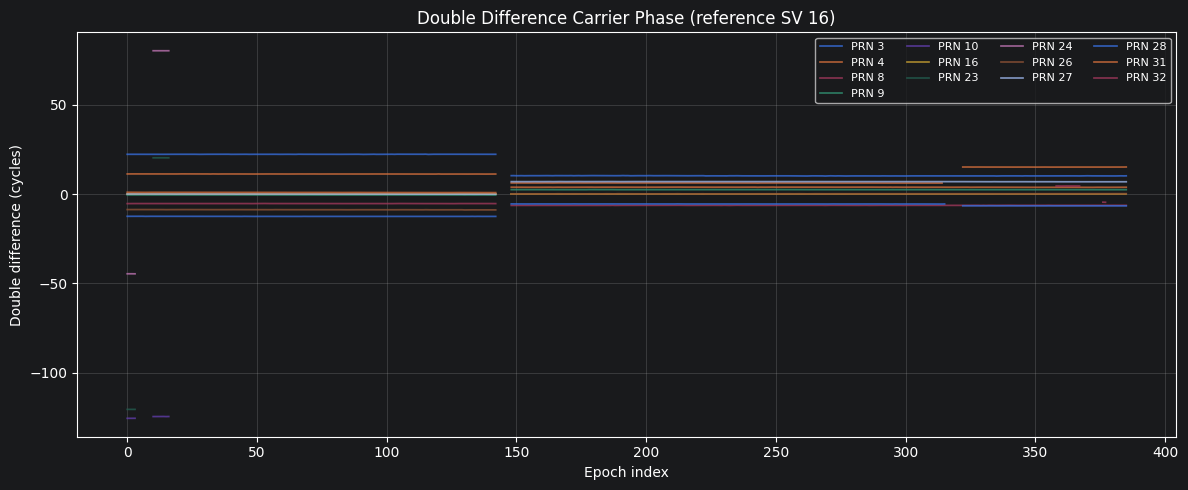

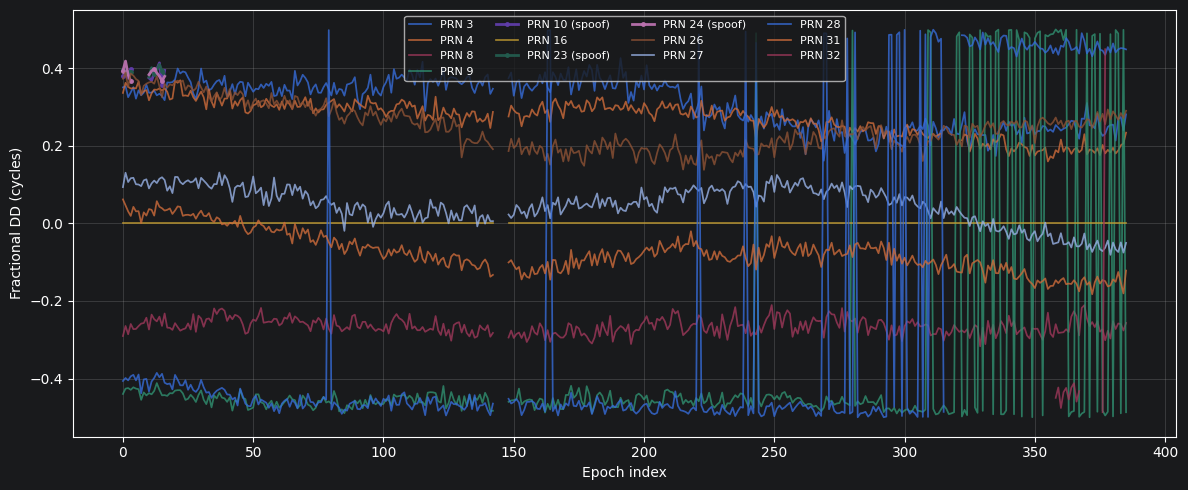

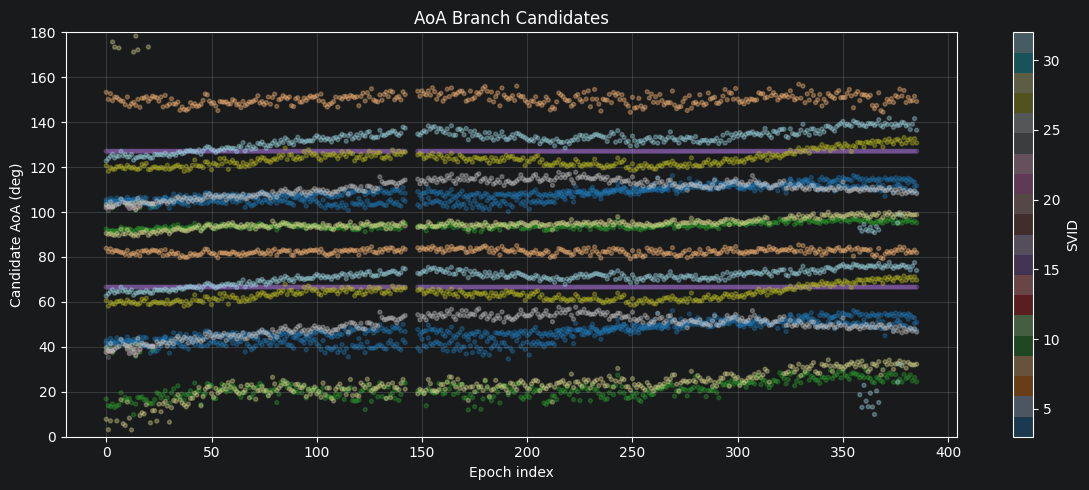

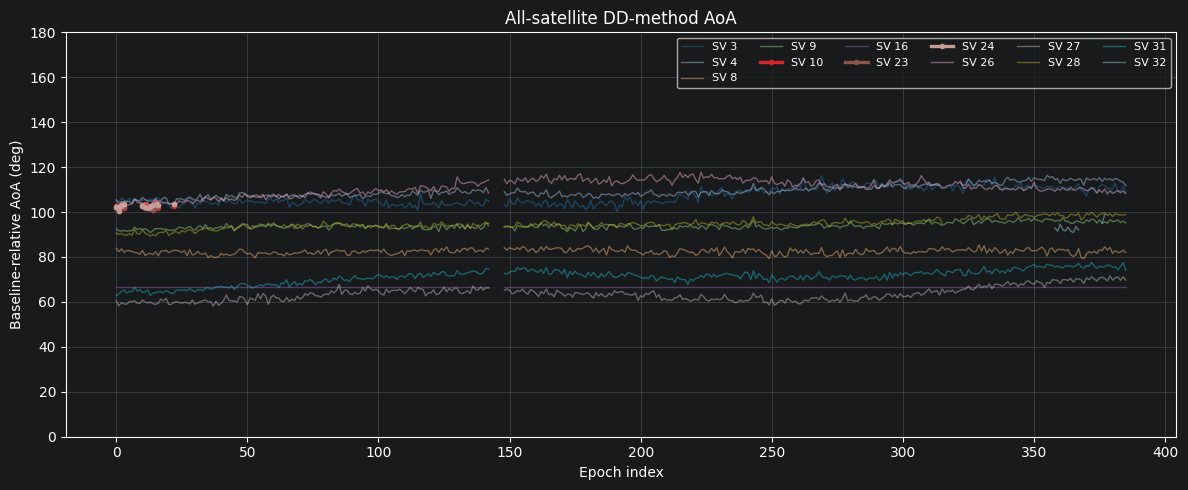

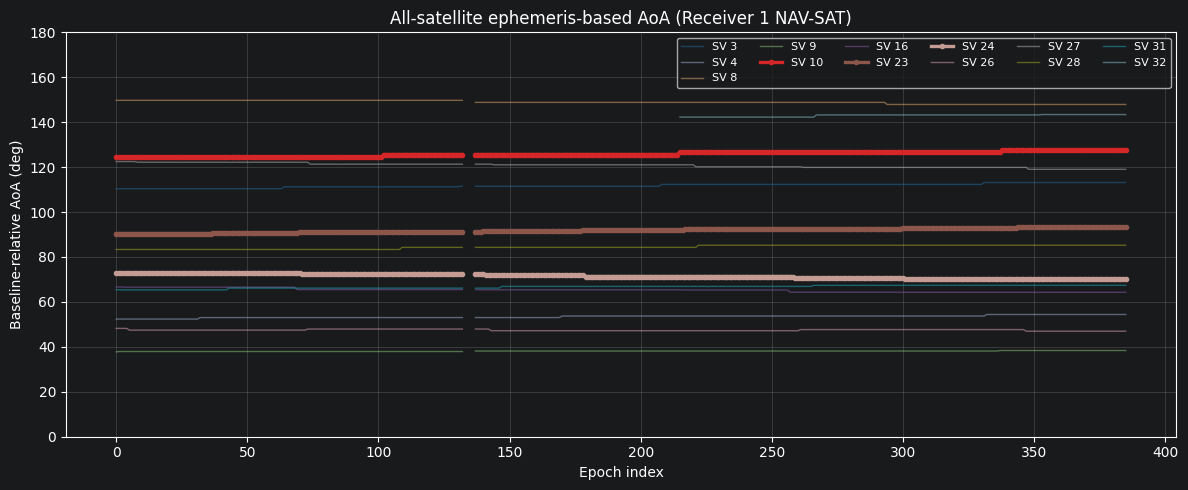

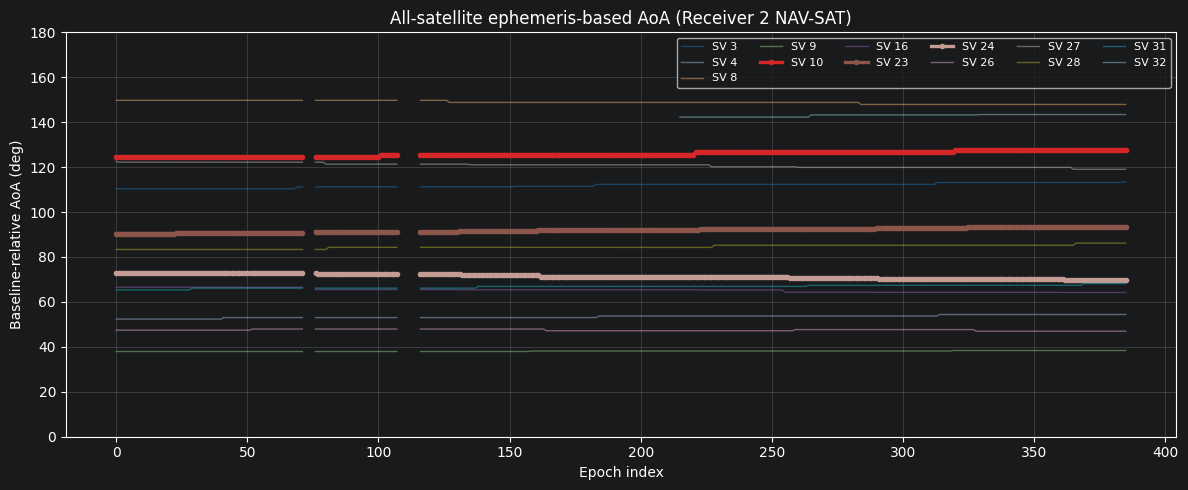

,svid,branch,valid_epoch_count,median_candidate_aoa_deg,mean_candidate_aoa_deg,min_candidate_aoa_deg,max_candidate_aoa_deg,median_candidate_cos_alpha,reference_epoch_count,median_reference_aoa_deg,median_abs_error_to_reference_deg,mean_abs_error_to_reference_deg,within_10deg_fraction,dp_selected_epoch_fraction
0,3,-1,381,105.836695,107.140058,100.182409,116.196488,-0.272896,377,111.469024,5.101864,4.769355,0.986737,1.000000
1,3,0,381,43.355878,44.889015,34.591820,56.044479,0.727104,377,111.469024,67.596032,66.838824,0.000000,0.000000
2,4,-1,374,108.627653,109.295151,103.534580,116.310059,-0.319417,370,53.723856,55.290287,55.829380,0.000000,1.000000
3,4,0,374,47.110758,47.838343,40.006830,56.167187,0.680583,370,53.723856,6.197247,5.679690,0.948649,0.000000
4,8,-1,381,150.273432,150.316476,144.435311,156.914892,-0.868402,377,148.815810,2.007920,2.382708,1.000000,0.000000
5,8,0,381,82.438037,82.416138,79.249032,85.407034,0.131598,377,148.815810,66.557960,66.511915,0.000000,1.000000
6,9,-1,42,96.454125,96.476317,95.912106,97.484636,-0.112408,42,38.375192,58.165545,58.179472,0.000000,1.000000
7,9,0,381,93.385455,86.319213,26.233860,95.895883,-0.059053,377,38.140150,55.376185,50.565364,0.023873,0.889764
8,9,1,339,20.431996,20.213319,9.809400,26.197330,0.937087,335,38.140150,17.582958,17.845510,0.000000,0.000000
9,10,-1,12,102.506561,102.592661,100.902207,104.226419,-0.216551,12,124.438488,21.931926,21.845827,0.000000,1.000000


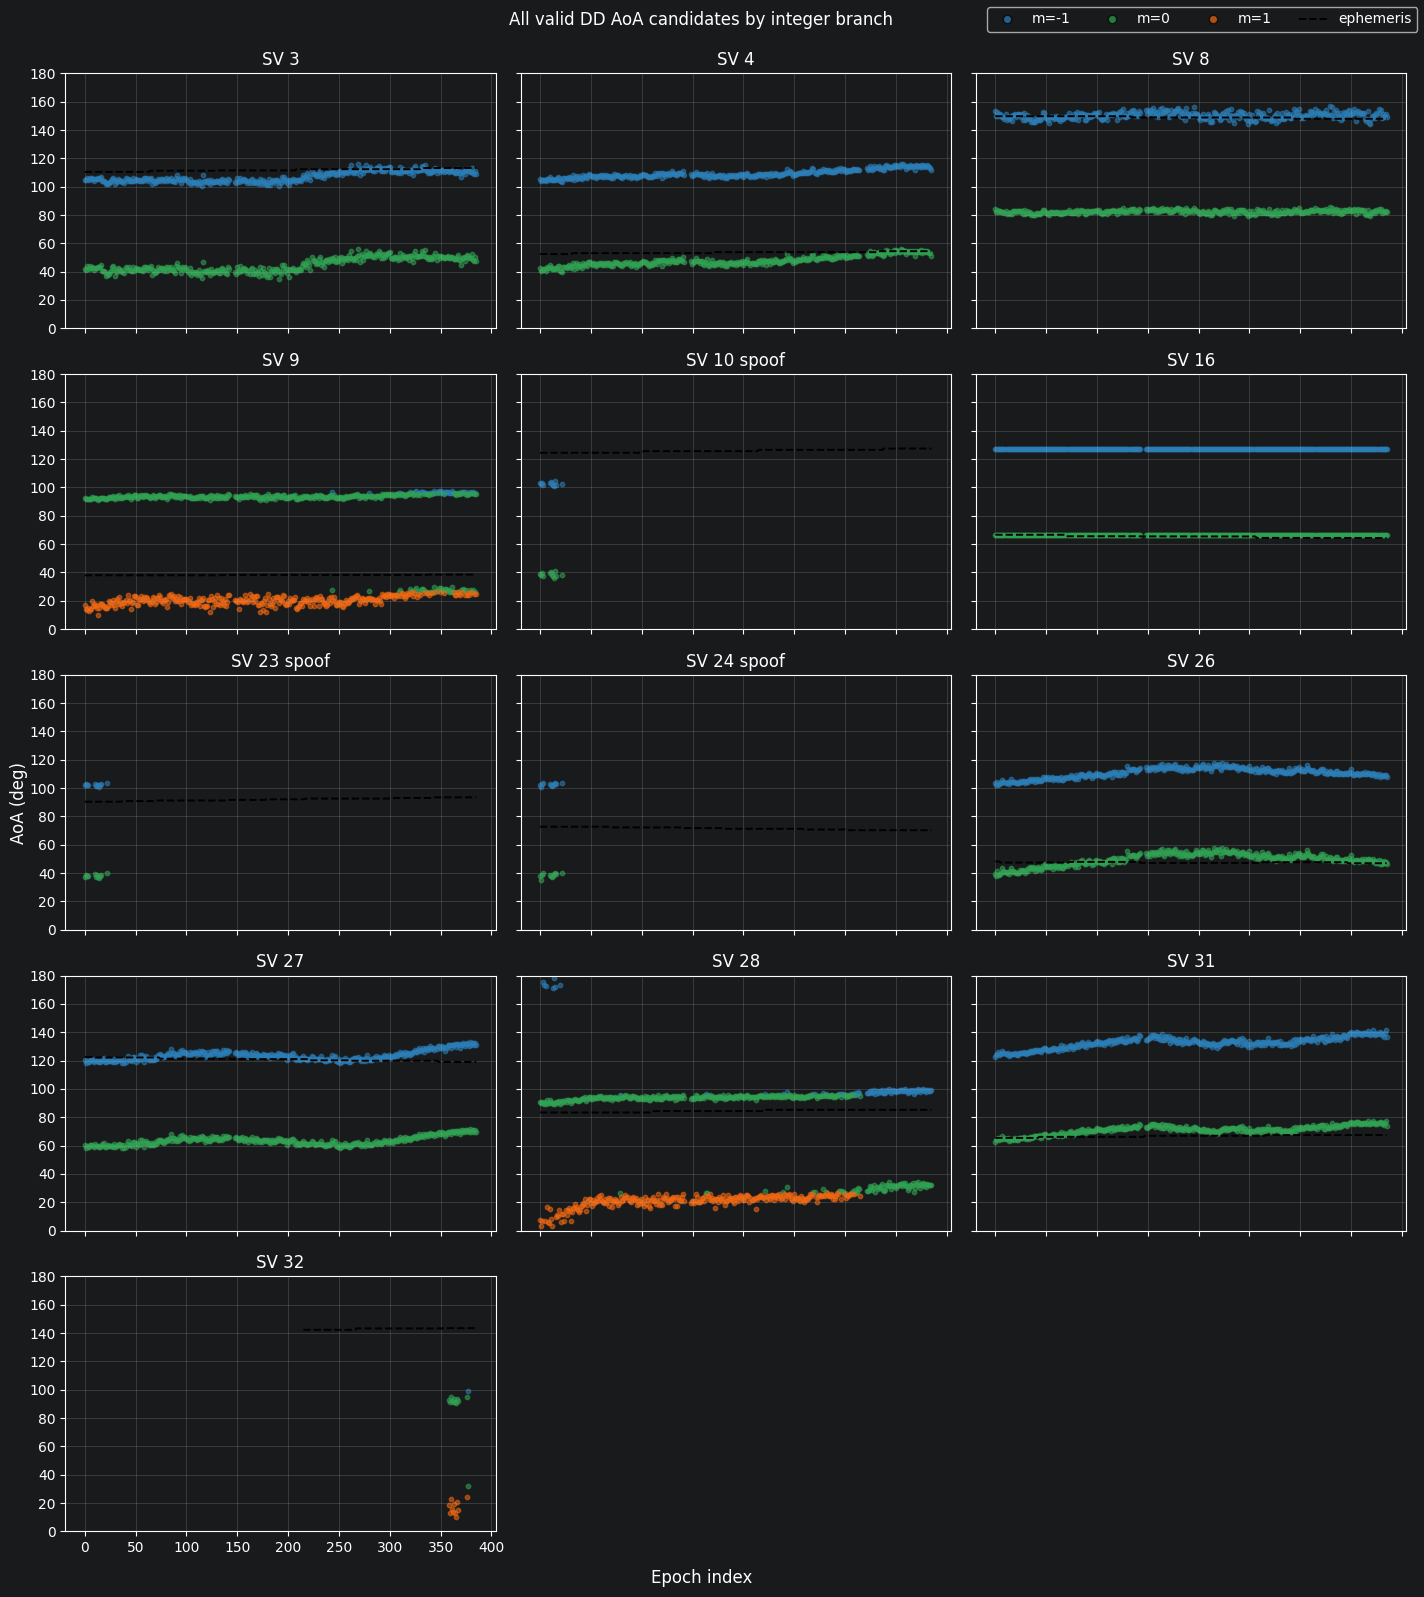

,svid,branch
0,3,-1
1,4,0
2,8,-1
3,9,1
4,10,-1
5,16,0
6,23,-1
7,24,-1
8,26,0
9,27,-1


,method,svid,branch,epoch_count,median_abs_error_deg,mean_abs_error_deg,p90_abs_error_deg,within_5deg_fraction,within_10deg_fraction
0,dp_smoothness,3,-1,377,5.101864,4.769355,8.224227,0.490716,0.986737
1,ephemeris_aligned_constant_m,3,-1,377,5.101864,4.769355,8.224227,0.490716,0.986737
2,dp_smoothness,4,-1,370,55.290287,55.829380,59.713262,0.000000,0.000000
3,ephemeris_aligned_constant_m,4,0,370,6.197247,5.679690,9.044311,0.364865,0.948649
4,dp_smoothness,8,0,377,66.557960,66.511915,68.506091,0.000000,0.000000
5,ephemeris_aligned_constant_m,8,-1,377,2.007920,2.382708,4.805540,0.917772,1.000000
6,dp_smoothness,9,0,377,55.701716,55.839648,57.597215,0.000000,0.000000
7,ephemeris_aligned_constant_m,9,1,335,17.582958,17.845510,21.904000,0.000000,0.000000
8,dp_smoothness,10,-1,12,21.931926,21.845827,22.565856,0.000000,0.000000
9,ephemeris_aligned_constant_m,10,-1,12,21.931926,21.845827,22.565856,0.000000,0.000000


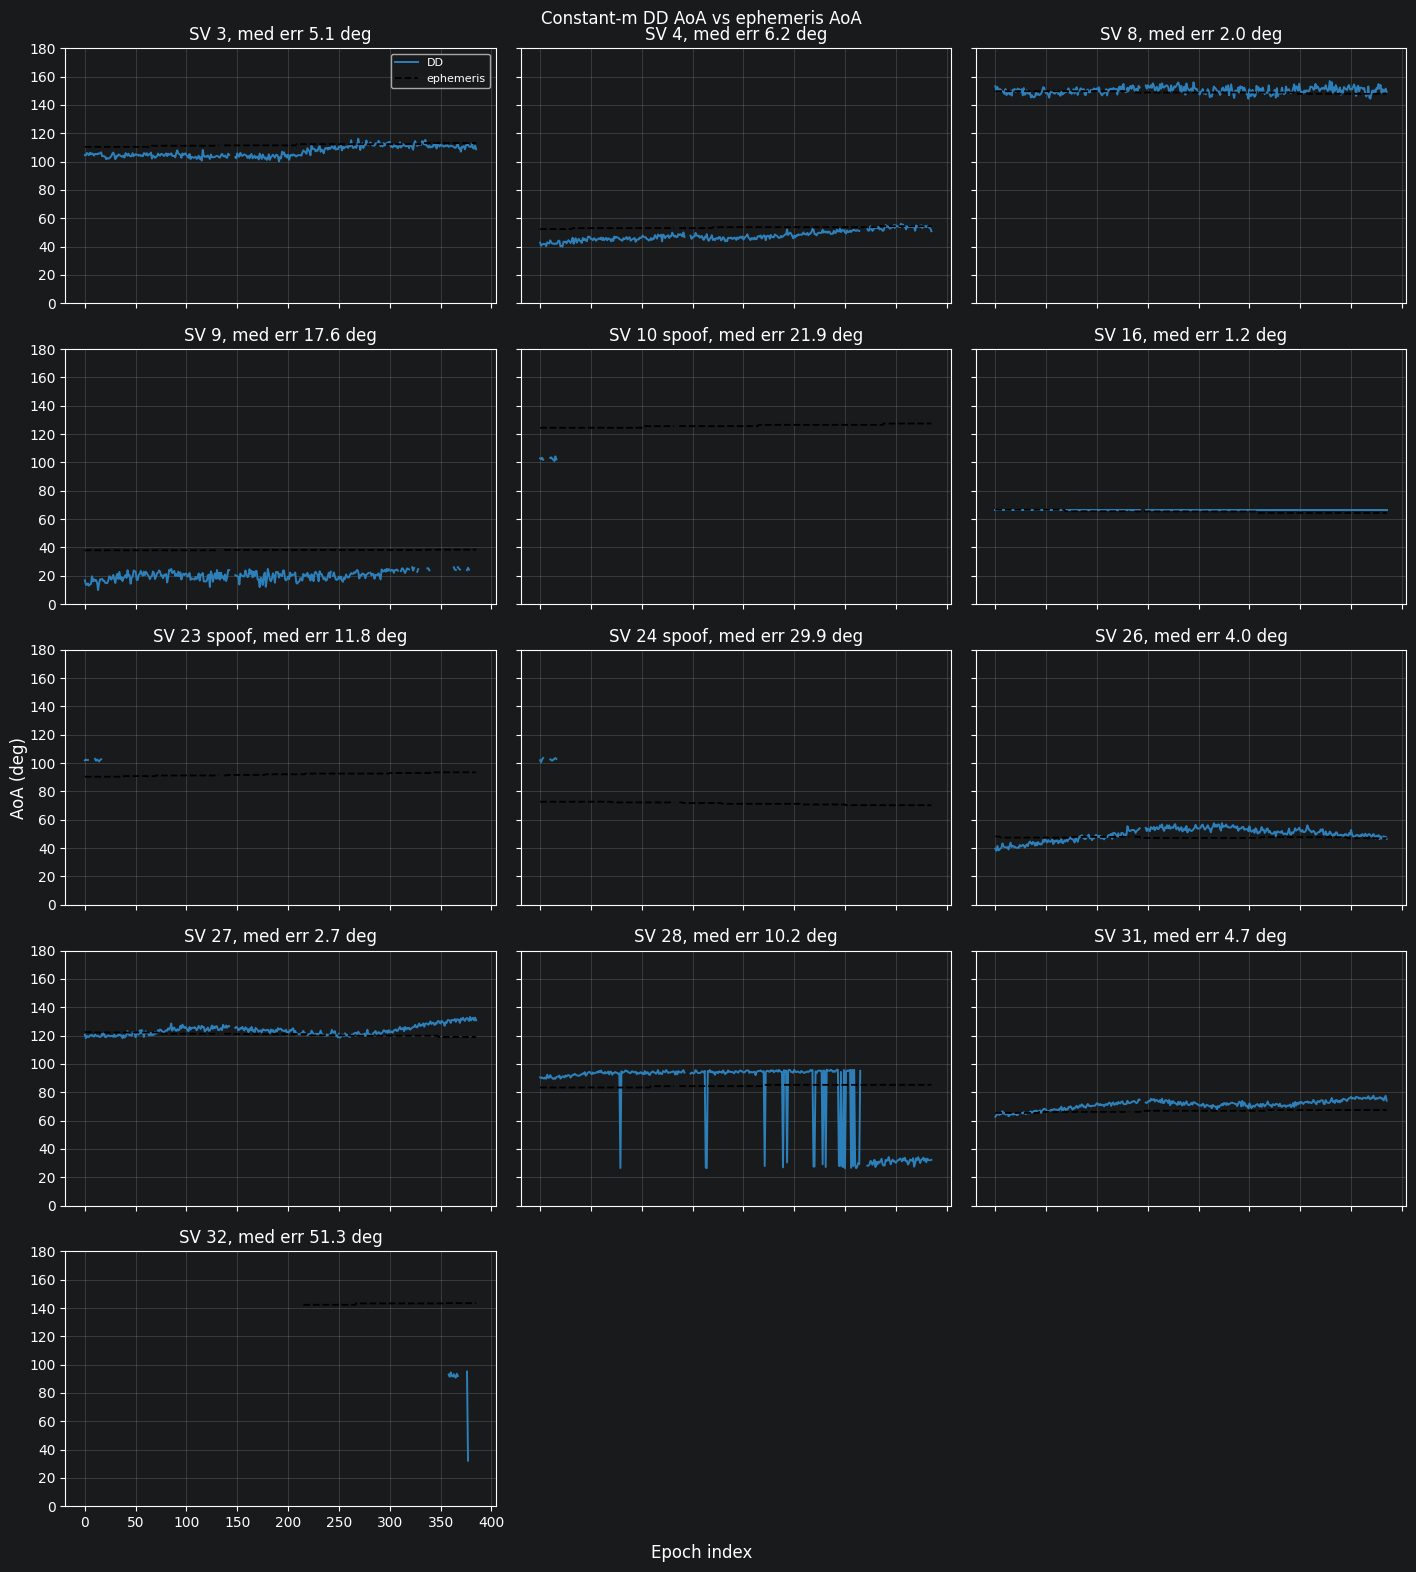

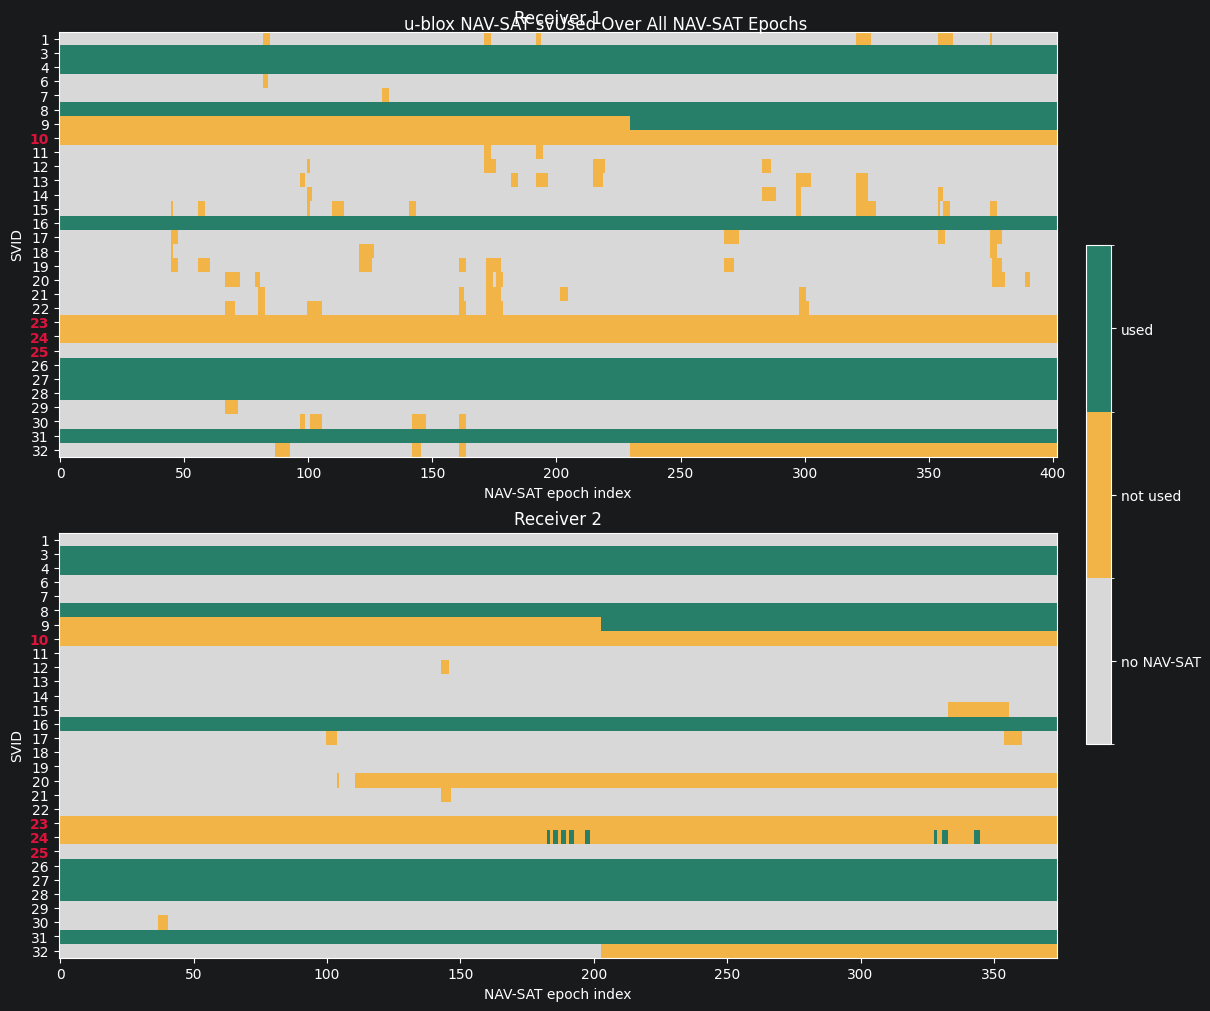

In [10]:
fig = plot_double_difference(result)
display(fig)
plt.close(fig)

fig = plot_fractional_dd(
    all_satellite_result,
    highlight_svids=SPOOF_SVIDS,
    title=None,
)
display(fig)
plt.close(fig)

if not result.candidate_aoa_deg.empty:
    fig = plot_candidate_cloud(result)
    display(fig)
    plt.close(fig)

if PARTIAL_SPOOF_ENABLED:
    fig = plot_aoa_tracks(
        scenario.joint_source_aoa_deg,
        title="Spoof-satellite joint-source DD-method AoA",
        highlight_svids=SPOOF_SVIDS,
    )
    display(fig)
    plt.close(fig)

if not scenario.all_satellite_dd_method_aoa_deg.empty:
    fig = plot_aoa_tracks(
        scenario.all_satellite_dd_method_aoa_deg,
        title="All-satellite DD-method AoA",
        highlight_svids=SPOOF_SVIDS,
    )
    display(fig)
    plt.close(fig)

fig = plot_aoa_tracks(
    scenario.ephemeris_aoa_rx1_deg,
    title="All-satellite ephemeris-based AoA (Receiver 1 NAV-SAT)",
    highlight_svids=SPOOF_SVIDS,
)
display(fig)
plt.close(fig)

fig = plot_aoa_tracks(
    scenario.ephemeris_aoa_rx2_deg,
    title="All-satellite ephemeris-based AoA (Receiver 2 NAV-SAT)",
    highlight_svids=SPOOF_SVIDS,
)
display(fig)
plt.close(fig)

if not scenario.all_satellite_valid_m_candidates.empty:
    display(scenario.all_satellite_valid_m_summary)
    fig = plot_valid_m_candidates(
        scenario.all_satellite_result.candidate_aoa_deg,
        reference_aoa=scenario.ephemeris_aoa_rx1_deg,
        title="All valid DD AoA candidates by integer branch",
        highlight_svids=SPOOF_SVIDS,
    )
    display(fig)
    plt.close(fig)

if not scenario.ephemeris_aligned_dd_method_aoa_deg.empty:
    display(scenario.ephemeris_aligned_branch)
    display(scenario.aoa_method_equivalence_summary)
    fig = plot_aoa_method_comparison(
        scenario.ephemeris_aligned_dd_method_aoa_deg,
        scenario.ephemeris_aoa_rx1_deg,
        title="Constant-m DD AoA vs ephemeris AoA",
        highlight_svids=SPOOF_SVIDS,
    )
    display(fig)
    plt.close(fig)

fig = plot_sv_used_timeline(
    {"Receiver 1": scenario.sv_used_rx1, "Receiver 2": scenario.sv_used_rx2},
    title="u-blox NAV-SAT svUsed Over All NAV-SAT Epochs",
    highlight_svids=SPOOF_SVIDS,
)
display(fig)
plt.close(fig)


## All-satellite Anchored DD-method AoA and Branch `m`

The notebook retains the paper's independently selected dynamic-programming tracks as an unconstrained diagnostic. DP minimizes change over time, but it has no absolute preference when it restarts after a dropout; a smooth `m=-1` path can therefore win even when `m=0` is physically expected.

For the separate **known all-spoof/common-source reconstruction**, every counterfeit signal is assumed to arrive from the same direction as PRN 6. Then `cos(alpha_i) - cos(alpha_r) = 0`, so Eq. 21 requires `m=0`. `full_spoof_fixed_m0_aoa_deg` is the best AoA visualization under that stated hypothesis. It must not be used as independent evidence that the signals are spoofed; use fractional-DD collapse for that evidence.

- The approximately 82-degree level is relative to the configured fixed PRN 6 angle. Replace that constant with a surveyed value to interpret the absolute bearing.
- RAWX samples with unresolved half-cycle ambiguity (`halfCyc=0`) are rejected before DD calculation; they previously produced the secondary 111-degree bands.
- Receiver `NAV-SAT` comparison plots are exploratory diagnostics only, not clean ephemeris validation.

The first figure is the fixed-`m=0` common-source reconstruction and is saved as `paper_full_spoof_fixed_m0_aoa.png`. The paper-DP and Receiver 1 `NAV-SAT` diagnostics follow separately.

The signed-difference tables are retained to expose disagreement and branch transitions, but their values must not be interpreted as errors against trusted ground truth in this full-spoof run.


Known common-source reconstruction (fixed m=0)


,10,23,24
epoch_index,,,
0,39.014205,37.564727,37.752612
1,38.126790,38.544809,35.370224
2,39.549426,37.915413,38.755630
3,37.409580,37.971025,40.205933
4,NaN,NaN,NaN


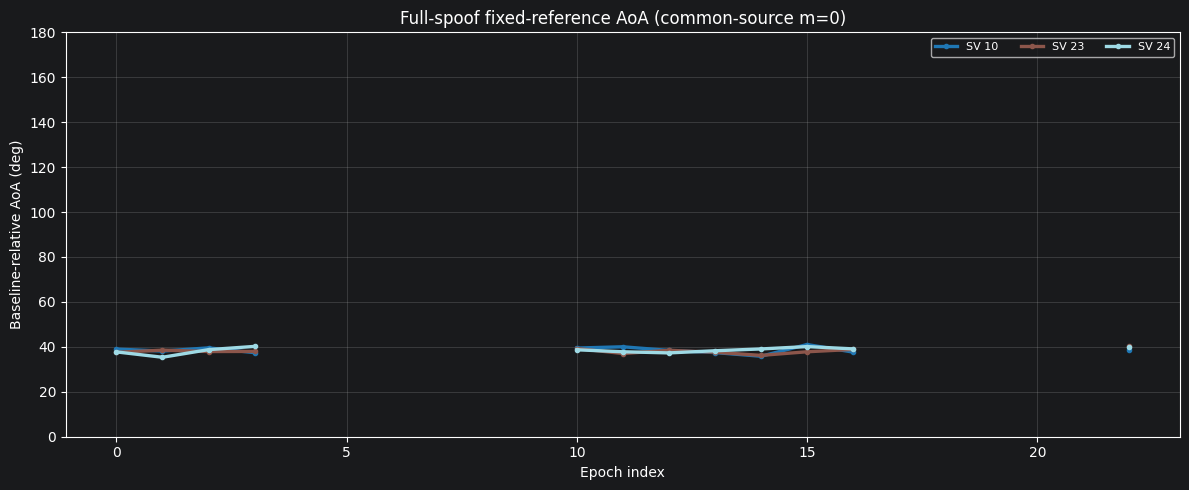

Paper DP diagnostic (branches selected independently by smoothness)


,3,4,8,9,10,16,23,24,26,27,28,31,32
epoch_index,,,,,,,,,,,,,
0,104.609378,42.829384,153.291470,16.790152,102.885891,66.6,101.966215,102.083580,39.660555,120.621127,90.525602,62.683463,NaN
1,104.448436,40.585819,150.154306,13.812463,102.318953,66.6,102.584483,100.636138,38.169655,118.186498,90.084140,63.662019,NaN
2,106.117805,41.477699,152.717273,13.444374,103.233756,66.6,102.185721,102.719431,41.532605,119.755883,90.433331,64.655116,NaN
3,105.376767,41.862704,149.571808,14.530915,101.869715,66.6,102.220706,103.666545,38.427247,119.109305,89.838242,65.394510,NaN
4,104.575664,41.758194,151.117520,12.957299,NaN,66.6,NaN,NaN,38.912951,119.039759,89.618664,63.916913,NaN


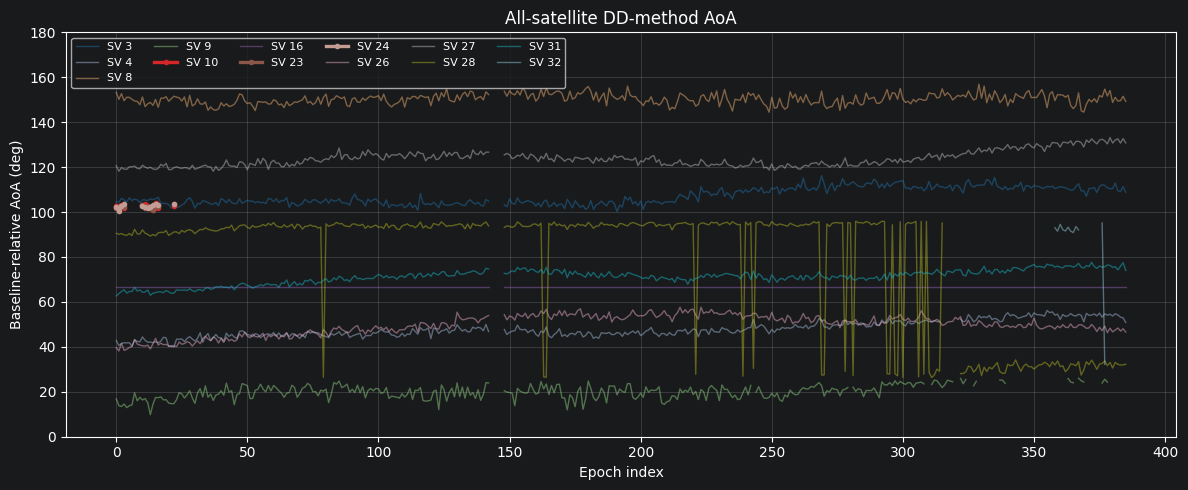

Ephemeris-method AoA for direct per-satellite comparison


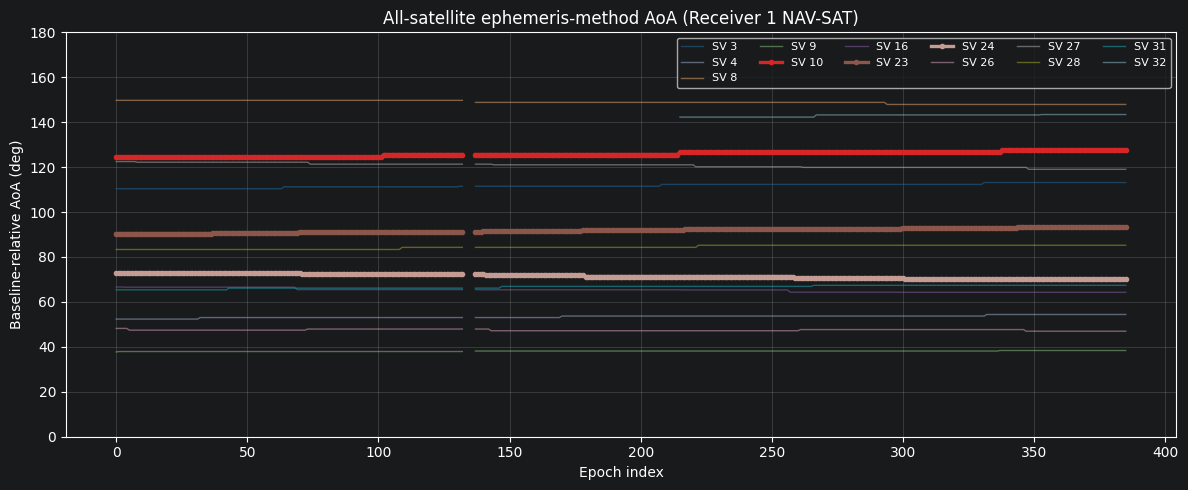

,signal_group,reconstruction_source,matches_source_track
svid,,,
3,authentic,best-m (ephemeris aligned),True
4,authentic,best-m (ephemeris aligned),True
8,authentic,best-m (ephemeris aligned),True
9,authentic,best-m (ephemeris aligned),True
10,spoof,DP,True
16,authentic,best-m (ephemeris aligned),True
23,spoof,DP,True
24,spoof,DP,True
26,authentic,best-m (ephemeris aligned),True


,signal_type,epoch_count,bias_deg,mae_deg,median_abs_error_deg,rmse_deg,p90_abs_error_deg,max_abs_error_deg,within_5deg_pct,within_10deg_pct
svid,,,,,,,,,,
3,authentic,377,-4.60,4.77,5.10,5.52,8.22,11.29,49.07,98.67
4,authentic,370,-5.63,5.68,6.20,6.42,9.04,12.36,36.49,94.86
8,authentic,377,1.37,2.38,2.01,2.94,4.81,9.02,91.78,100.00
9,authentic,335,-17.85,17.85,17.58,18.11,21.90,28.12,0.00,0.00
10,spoof,12,-21.85,21.85,21.93,21.86,22.57,23.54,0.00,0.00
16,authentic,377,1.36,1.36,1.19,1.58,2.33,2.33,100.00,100.00
23,spoof,12,11.90,11.90,11.78,11.91,12.60,13.22,0.00,0.00
24,spoof,12,29.84,29.84,29.94,29.85,30.86,30.90,0.00,0.00
26,authentic,377,2.26,4.27,4.00,5.02,7.71,10.47,59.95,99.20


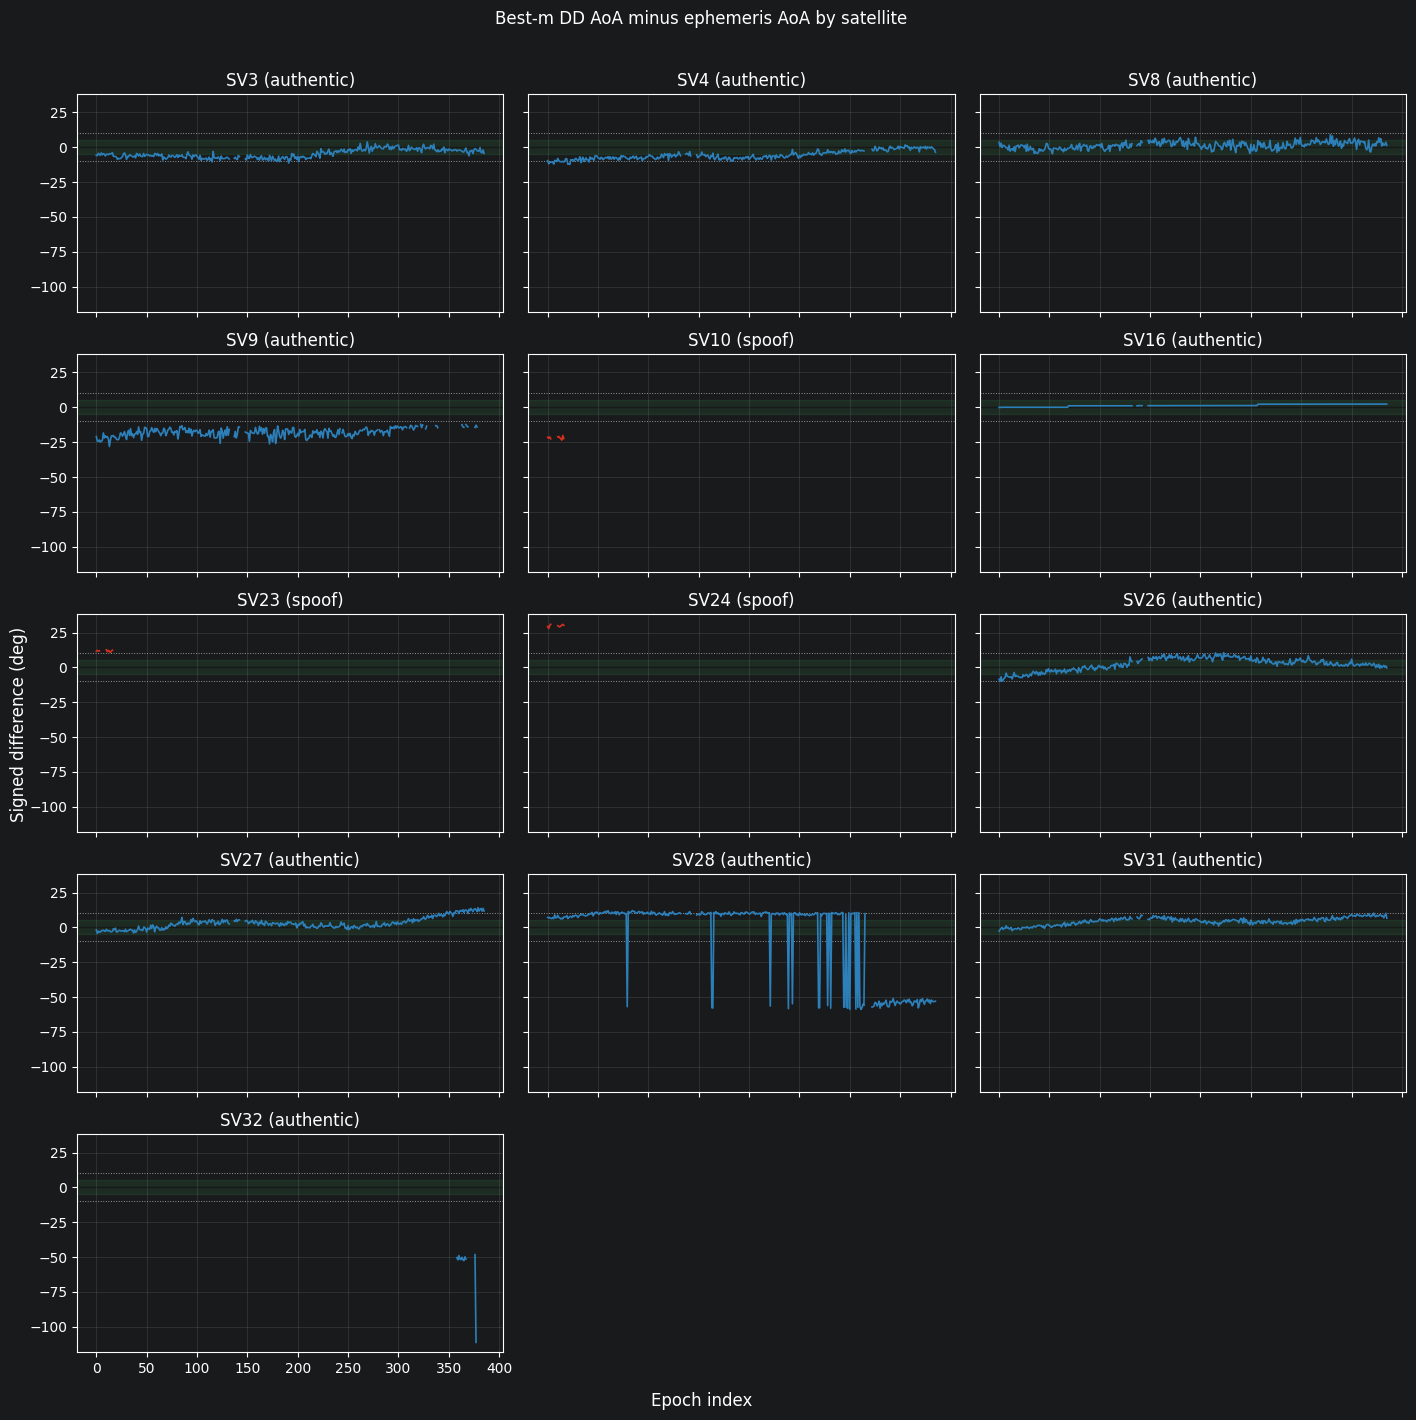

/var/folders/36/tkc64gps38s9nzp5s6dtqkpw0000gn/T/ipykernel_76416/1593313527.py:150: UserWarning: Glyph 65023 (\N{ARABIC LIGATURE AZZA WA JALL}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/36/tkc64gps38s9nzp5s6dtqkpw0000gn/T/ipykernel_76416/1593313527.py:151: UserWarning: Glyph 65023 (\N{ARABIC LIGATURE AZZA WA JALL}) missing from font(s) DejaVu Sans.
  fig.savefig(
/Users/betty/Developer/research/angle/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 65023 (\N{ARABIC LIGATURE AZZA WA JALL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


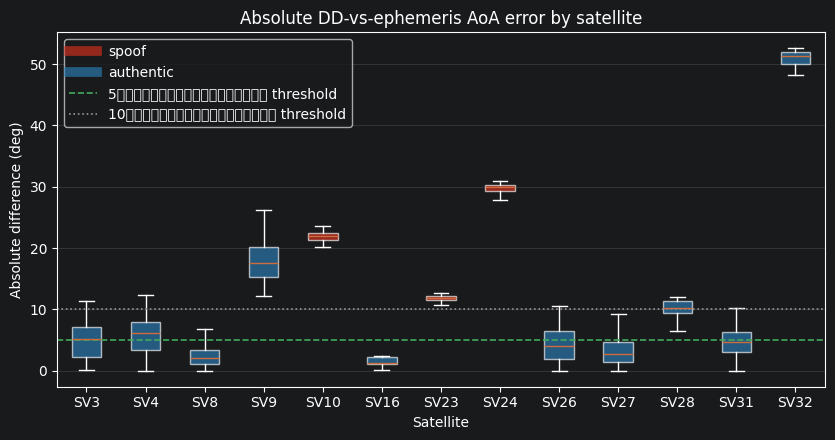

In [11]:
if not PARTIAL_SPOOF_ENABLED and not full_spoof_fixed_m0_aoa_deg.empty:
    print("Known common-source reconstruction (fixed m=0)")
    display(full_spoof_fixed_m0_aoa_deg.head())
    fig = plot_aoa_tracks(
        full_spoof_fixed_m0_aoa_deg,
        title="Full-spoof fixed-reference AoA (common-source m=0)",
        highlight_svids=SPOOF_SVIDS,
    )
    fig.savefig(
        SCENARIO_CONFIG.output_dir / "paper_full_spoof_fixed_m0_aoa.png",
        dpi=180, bbox_inches="tight",
    )
    display(fig)
    plt.close(fig)

if not scenario.best_m_all_satellite_aoa_deg.empty:
    print("Paper DP diagnostic (branches selected independently by smoothness)")
    display(scenario.best_m_all_satellite_aoa_deg.head())
    fig = plot_aoa_tracks(
        scenario.best_m_all_satellite_aoa_deg,
        title="All-satellite DD-method AoA",
        highlight_svids=SPOOF_SVIDS,
    )
    display(fig)
    plt.close(fig)

    print("Ephemeris-method AoA for direct per-satellite comparison")
    fig = plot_aoa_tracks(
        scenario.ephemeris_aoa_rx1_deg,
        title="All-satellite ephemeris-method AoA (Receiver 1 NAV-SAT)",
        highlight_svids=SPOOF_SVIDS,
    )
    display(fig)
    plt.close(fig)

    # Confirm which source reconstructs each final satellite track.
    reconstruction_rows = []
    ephemeris_aligned_svids = set(map(int, scenario.ephemeris_aligned_dd_method_aoa_deg.columns))
    for svid in map(int, scenario.best_m_all_satellite_aoa_deg.columns):
        use_dp = svid in SPOOF_SVIDS or svid not in ephemeris_aligned_svids
        source_frame = (
            scenario.all_satellite_dd_method_aoa_deg
            if use_dp
            else scenario.ephemeris_aligned_dd_method_aoa_deg
        )
        final_track = scenario.best_m_all_satellite_aoa_deg[svid]
        expected_track = source_frame[svid].reindex(final_track.index)
        reconstruction_rows.append(
            {
                "svid": svid,
                "signal_group": "spoof" if svid in SPOOF_SVIDS else "authentic",
                "reconstruction_source": (
                    "DP" if svid in SPOOF_SVIDS else "DP fallback (no ephemeris)"
                ) if use_dp else "best-m (ephemeris aligned)",
                "matches_source_track": final_track.equals(expected_track),
            }
        )
    reconstruction_confirmation = pd.DataFrame(reconstruction_rows).set_index("svid")
    assert reconstruction_confirmation["matches_source_track"].all()
    display(reconstruction_confirmation)

    # Compare only shared satellites and epochs; signed error = DD method - ephemeris.
    shared_svids = sorted(
        set(map(int, scenario.best_m_all_satellite_aoa_deg.columns))
        & set(map(int, scenario.ephemeris_aoa_rx1_deg.columns))
    )
    best_m_dd = scenario.best_m_all_satellite_aoa_deg.reindex(columns=shared_svids)
    ephemeris = scenario.ephemeris_aoa_rx1_deg.reindex(columns=shared_svids)
    dd_ephemeris_diff_deg = best_m_dd.subtract(ephemeris)

    error_rows = []
    for svid in shared_svids:
        signed_error = dd_ephemeris_diff_deg[svid].dropna()
        abs_error = signed_error.abs()
        error_rows.append(
            {
                "svid": svid,
                "signal_type": "spoof" if svid in SPOOF_SVIDS else "authentic",
                "epoch_count": len(signed_error),
                "bias_deg": signed_error.mean(),
                "mae_deg": abs_error.mean(),
                "median_abs_error_deg": abs_error.median(),
                "rmse_deg": (signed_error.pow(2).mean()) ** 0.5,
                "p90_abs_error_deg": abs_error.quantile(0.90),
                "max_abs_error_deg": abs_error.max(),
                "within_5deg_pct": 100 * abs_error.le(5).mean(),
                "within_10deg_pct": 100 * abs_error.le(10).mean(),
            }
        )

    dd_ephemeris_error_summary = pd.DataFrame(error_rows).set_index("svid")
    display(dd_ephemeris_error_summary.round(2))

    output_dir = SCENARIO_CONFIG.output_dir
    dd_ephemeris_diff_deg.to_csv(output_dir / "paper_best_m_dd_minus_ephemeris_deg.csv", index=True)
    dd_ephemeris_error_summary.to_csv(
        output_dir / "paper_best_m_dd_vs_ephemeris_error_summary.csv", index=True
    )

    ncols = min(3, len(shared_svids))
    nrows = (len(shared_svids) + ncols - 1) // ncols
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(4.8 * ncols, 2.8 * nrows), sharex=True, sharey=True
    )
    axes = [axes] if nrows * ncols == 1 else axes.ravel()
    for ax, svid in zip(axes, shared_svids):
        color = "#d7301f" if svid in SPOOF_SVIDS else "#2c7fb8"
        ax.axhspan(-5, 5, color="#41ab5d", alpha=0.12, label="within ﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿5﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿")
        ax.axhline(0, color="black", lw=0.8, zorder=1)
        ax.axhline(10, color="#969696", lw=0.7, ls=":")
        ax.axhline(-10, color="#969696", lw=0.7, ls=":")
        if dd_ephemeris_diff_deg[svid].notna().any():
            ax.plot(
                dd_ephemeris_diff_deg.index, dd_ephemeris_diff_deg[svid],
                color=color, lw=1.2, zorder=2,
            )
        else:
            ax.text(0.5, 0.5, "No shared data", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(f"SV{svid} ({'spoof' if svid in SPOOF_SVIDS else 'authentic'})")
        ax.grid(alpha=0.2)
    for ax in axes[len(shared_svids):]:
        ax.axis("off")
    fig.suptitle("Best-m DD AoA minus ephemeris AoA by satellite", y=1.01)
    fig.supxlabel("Epoch index")
    fig.supylabel("Signed difference (deg)")
    fig.tight_layout()
    fig.savefig(
        output_dir / "paper_best_m_dd_minus_ephemeris_by_satellite.png",
        dpi=180, bbox_inches="tight",
    )
    display(fig)
    plt.close(fig)

    plotted_svids = [svid for svid in shared_svids if dd_ephemeris_diff_deg[svid].notna().any()]
    error_series = [dd_ephemeris_diff_deg[svid].dropna().abs() for svid in plotted_svids]
    fig, ax = plt.subplots(figsize=(max(8, 0.65 * len(plotted_svids)), 4.5))
    boxes = ax.boxplot(error_series, tick_labels=[f"SV{svid}" for svid in plotted_svids], showfliers=False, patch_artist=True)
    for box, svid in zip(boxes["boxes"], plotted_svids):
        box.set_facecolor("#d7301f" if svid in SPOOF_SVIDS else "#2c7fb8")
        box.set_alpha(0.65)
    ax.plot([], [], color="#d7301f", lw=7, alpha=0.65, label="spoof")
    ax.plot([], [], color="#2c7fb8", lw=7, alpha=0.65, label="authentic")
    ax.axhline(5, color="#41ab5d", lw=1.2, ls="--", label="5﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿ threshold")
    ax.axhline(10, color="#969696", lw=1.2, ls=":", label="10﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿ threshold")
    ax.set_title("Absolute DD-vs-ephemeris AoA error by satellite")
    ax.set_xlabel("Satellite")
    ax.set_ylabel("Absolute difference (deg)")
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(
        output_dir / "paper_best_m_dd_vs_ephemeris_absolute_error.png",
        dpi=180, bbox_inches="tight",
    )
    display(fig)
    plt.close(fig)


## Mixed-Tracking Pairwise Classifier (Skipped for Full Spoof)

The following code cell is preserved for the older labelled mixed-tracking experiment and executes only when `PARTIAL_SPOOF_ENABLED = True`. It is skipped here because this capture has no authentic comparison class and receiver `NAV-SAT` is not clean ground truth.

The residual is computed in the direction-cosine domain exactly as defined by manuscript Eq. (32). Because no independent authentic calibration recording is currently available, automatic label-based threshold tuning is not used. The code instead exposes one manual constant, HARD_CODED_PAIRWISE_THRESHOLD = 0.20. Change that constant to test another operating point.

The score threshold remains fixed at $\eta=0.5$. The hard-coded $\tau_q$ is unitless because it thresholds direction-cosine residuals. The diagnostics report every threshold interval and its resulting PRN groups, but they do not select a threshold automatically.

For interpretability, the diagnostics list every consistent and inconsistent partner of each PRN. In the journal baseline, a pair is consistent exactly when its aggregated Eq. (32) residual satisfies $q_{ij} \leq \tau_q$; the satellite score is the number of consistent partners divided by all available partners. The following section adds the minimal common-direction penalty requested here while retaining this baseline unchanged for a direct before-and-after comparison.

A fixed DD reference has no DD reconstruction of itself and is consequently excluded from a single-reference run, leaving ten classified targets and nine possible partners per target. Filling the manuscript's 11-satellite Table 3 requires the multiple-reference aggregation reported below.


In [12]:
_MIXED_TRACKING_CLASSIFIER_SOURCE = r"""
AUTHENTIC_SVIDS = (10, 12, 15, 18, 23, 24, 32)
PAPER_SVIDS = tuple(sorted((*SPOOF_SVIDS, *AUTHENTIC_SVIDS)))
assert set(SPOOF_SVIDS).isdisjoint(AUTHENTIC_SVIDS)
GROUND_TRUTH_BY_SVID = {
    svid: ("Counterfeit" if svid in SPOOF_SVIDS else "Authentic")
    for svid in PAPER_SVIDS
}

# Manual operating value. Change this constant to inspect another tau_q.
HARD_CODED_PAIRWISE_THRESHOLD = 0.20

def geometry_tracks_from_wide(dd_aoa_deg, method):
    target_svids = [
        svid for svid in PAPER_SVIDS
        if svid != HARDCODED_REFERENCE_SVID
        and svid in dd_aoa_deg.columns
        and svid in scenario.ephemeris_aoa_rx1_deg.columns
    ]
    dd_long = (
        dd_aoa_deg.reindex(columns=target_svids)
        .rename_axis(index="epoch_index", columns="svid")
        .stack(future_stack=True).rename("dd_aoa_deg").reset_index()
    )
    eph_long = (
        scenario.ephemeris_aoa_rx1_deg.reindex(columns=target_svids)
        .rename_axis(index="epoch_index", columns="svid")
        .stack(future_stack=True).rename("ephemeris_aoa_deg").reset_index()
    )
    tracks = dd_long.merge(eph_long, on=["epoch_index", "svid"], how="inner").dropna()
    tracks.insert(0, "reference_svid", HARDCODED_REFERENCE_SVID)
    tracks.insert(1, "branch_selection_method", method)
    tracks["dd_direction_cosine"] = np.cos(np.deg2rad(tracks["dd_aoa_deg"]))
    tracks["ephemeris_direction_cosine"] = np.cos(np.deg2rad(tracks["ephemeris_aoa_deg"]))
    tracks["signed_geometry_error"] = (
        tracks["dd_direction_cosine"] - tracks["ephemeris_direction_cosine"]
    )
    return tracks

def attach_ground_truth(scores):
    scores = scores.copy()
    scores["ground_truth"] = scores["svid"].map(GROUND_TRUTH_BY_SVID)
    assert scores["ground_truth"].notna().all()
    scores["correct"] = scores["decision"].eq(scores["ground_truth"])
    return scores

def summarize_labelled_scores(scores, tau_p, eta):
    labelled = attach_ground_truth(scores)
    authentic = labelled[labelled["ground_truth"].eq("Authentic")]
    counterfeit = labelled[labelled["ground_truth"].eq("Counterfeit")]
    authentic_rate = authentic["correct"].mean()
    counterfeit_rate = counterfeit["correct"].mean()
    return {
        "tau_p_direction_cosine": float(tau_p),
        "eta": float(eta),
        "authentic_correct": int(authentic["correct"].sum()),
        "authentic_total": len(authentic),
        "authentic_acceptance_pct": 100 * authentic_rate,
        "counterfeit_correct": int(counterfeit["correct"].sum()),
        "counterfeit_total": len(counterfeit),
        "counterfeit_detection_pct": 100 * counterfeit_rate,
        "minimum_class_accuracy_pct": 100 * min(authentic_rate, counterfeit_rate),
        "balanced_accuracy_pct": 50 * (authentic_rate + counterfeit_rate),
        "overall_correct": int(labelled["correct"].sum()),
        "overall_total": len(labelled),
        "overall_accuracy_pct": 100 * labelled["correct"].mean(),
    }

def score_threshold_candidates(possible_pair_count):
    score_levels = np.arange(possible_pair_count + 1) / possible_pair_count
    midpoints = (score_levels[:-1] + score_levels[1:]) / 2.0
    return np.unique(np.concatenate((score_levels, midpoints)))

def scenario_threshold_candidates(aggregated):
    values = np.sort(aggregated["aggregated_pairwise_residual"].dropna().unique())
    if len(values) == 0:
        raise ValueError("No pairwise residuals are available for threshold selection.")
    lower = max(0.0, float(values[0]) / 2.0)
    midpoints = (values[:-1] + values[1:]) / 2.0
    upper_gap = float(values[-1] - values[-2]) if len(values) > 1 else max(float(values[-1]), 1.0)
    upper = float(values[-1]) + upper_gap / 2.0
    return np.concatenate(([lower], midpoints, [upper]))

def evaluate_pairwise_thresholds(aggregated):
    rows = []
    candidates = np.unique(
        np.append(
            scenario_threshold_candidates(aggregated),
            HARD_CODED_PAIRWISE_THRESHOLD,
        )
    )
    for tau_p in candidates:
        candidate_scores, _, _ = classify_pairwise_geometry(
            aggregated,
            pairwise_threshold=float(tau_p),
            score_threshold=SCORE_THRESHOLD,
            min_pair_coverage=1.0,
        )
        metrics = summarize_labelled_scores(candidate_scores, tau_p, SCORE_THRESHOLD)
        metrics["hard_coded_threshold"] = bool(
            np.isclose(tau_p, HARD_CODED_PAIRWISE_THRESHOLD)
        )
        rows.append(metrics)
    return pd.DataFrame(rows).sort_values(
        "tau_p_direction_cosine"
    ).reset_index(drop=True)

method = "hybrid_best_m"
tracks = geometry_tracks_from_wide(scenario.best_m_all_satellite_aoa_deg, method)
epoch_residuals = compute_pairwise_geometry_residuals(
    tracks, residual_domain="direction_cosine"
)
by_reference, aggregated = aggregate_pairwise_geometry_residuals(
    epoch_residuals, min_epochs_per_reference=10, min_references_per_pair=1
)
selected_tau_p = HARD_CODED_PAIRWISE_THRESHOLD
threshold_search = evaluate_pairwise_thresholds(aggregated)
scores, residual_matrix, consistency_matrix = classify_pairwise_geometry(
    aggregated,
    pairwise_threshold=selected_tau_p,
    score_threshold=SCORE_THRESHOLD,
    min_pair_coverage=1.0,
)
scores = attach_ground_truth(scores)

signal_error_summary = (
    tracks.groupby("svid", as_index=True)["signed_geometry_error"]
    .agg(
        median_signed_geometry_error="median",
        mean_signed_geometry_error="mean",
        signed_geometry_error_std="std",
    )
)
epoch_pair_summary = (
    epoch_residuals.groupby(["left_svid", "right_svid"], as_index=False)
    .agg(
        median_measured_relative_direction_cosine=(
            "measured_relative_direction_cosine", "median"
        ),
        median_expected_relative_direction_cosine=(
            "expected_relative_direction_cosine", "median"
        ),
    )
)
pair_details = aggregated.merge(
    epoch_pair_summary, on=["left_svid", "right_svid"], how="left"
)
pair_details["left_median_signed_geometry_error"] = pair_details["left_svid"].map(
    signal_error_summary["median_signed_geometry_error"]
)
pair_details["right_median_signed_geometry_error"] = pair_details["right_svid"].map(
    signal_error_summary["median_signed_geometry_error"]
)
pair_details["median_signed_error_separation"] = (
    pair_details["left_median_signed_geometry_error"]
    - pair_details["right_median_signed_geometry_error"]
).abs()
pair_details["left_ground_truth"] = pair_details["left_svid"].map(
    GROUND_TRUTH_BY_SVID
)
pair_details["right_ground_truth"] = pair_details["right_svid"].map(
    GROUND_TRUTH_BY_SVID
)
pair_details["pair_type"] = pair_details.apply(
    lambda row: "counterfeit-counterfeit"
    if row.left_ground_truth == row.right_ground_truth == "Counterfeit"
    else (
        "authentic-authentic"
        if row.left_ground_truth == row.right_ground_truth == "Authentic"
        else "mixed"
    ),
    axis=1,
)
pair_details["consistent"] = pair_details["aggregated_pairwise_residual"].le(
    selected_tau_p
)
pair_details["threshold_margin"] = (
    selected_tau_p - pair_details["aggregated_pairwise_residual"]
)
pair_details["consistency_reason"] = pair_details.apply(
    lambda row: (
        f"q={row.aggregated_pairwise_residual:.4f} <= tau={selected_tau_p:.4f}"
        if row.consistent
        else f"q={row.aggregated_pairwise_residual:.4f} > tau={selected_tau_p:.4f}"
    ),
    axis=1,
)
pair_details = pair_details.sort_values(
    ["consistent", "aggregated_pairwise_residual"], ascending=[False, True]
).reset_index(drop=True)

def format_partner_list(svid, consistent):
    relevant = pair_details.loc[
        (pair_details["left_svid"].eq(svid) | pair_details["right_svid"].eq(svid))
        & pair_details["consistent"].eq(consistent)
    ].copy()
    if relevant.empty:
        return "None"
    relevant["partner_svid"] = relevant.apply(
        lambda row: int(row.right_svid) if int(row.left_svid) == svid else int(row.left_svid),
        axis=1,
    )
    relevant = relevant.sort_values("aggregated_pairwise_residual")
    return "; ".join(
        f"PRN {int(row.partner_svid)} (q={row.aggregated_pairwise_residual:.4f})"
        for row in relevant.itertuples()
    )

satellite_detail_rows = []
for score_row in scores.sort_values("svid").itertuples():
    comparison = ">=" if score_row.consistency_score >= SCORE_THRESHOLD else "<"
    satellite_detail_rows.append(
        {
            "svid": int(score_row.svid),
            "ground_truth": score_row.ground_truth,
            "median_signed_geometry_error": signal_error_summary.loc[
                int(score_row.svid), "median_signed_geometry_error"
            ],
            "consistent_pair_count": int(score_row.consistent_pair_count),
            "possible_pair_count": int(score_row.possible_pair_count),
            "consistency_score": score_row.consistency_score,
            "consistent_with": format_partner_list(int(score_row.svid), True),
            "inconsistent_with": format_partner_list(int(score_row.svid), False),
            "score_decision_reason": (
                f"{score_row.consistent_pair_count}/{score_row.possible_pair_count}"
                f"={score_row.consistency_score:.3f} {comparison} eta={SCORE_THRESHOLD:.3f}"
            ),
            "decision": score_row.decision,
            "correct": score_row.correct,
        }
    )
satellite_consistency_details = pd.DataFrame(satellite_detail_rows)

eta_candidates = score_threshold_candidates(int(scores["possible_pair_count"].max()))
score_threshold_rows = []
for eta in eta_candidates:
    eta_scores, _, _ = classify_pairwise_geometry(
        aggregated,
        pairwise_threshold=selected_tau_p,
        score_threshold=float(eta),
        min_pair_coverage=1.0,
    )
    metrics = summarize_labelled_scores(eta_scores, selected_tau_p, eta)
    metrics["current_score_threshold"] = bool(np.isclose(eta, SCORE_THRESHOLD))
    score_threshold_rows.append(metrics)
score_threshold_sensitivity = pd.DataFrame(score_threshold_rows)

summary = threshold_search.loc[
    threshold_search["hard_coded_threshold"]
].iloc[0].to_dict()
summary.update(
    {
        "method": method,
        "reference_svid": HARDCODED_REFERENCE_SVID,
        "residual_domain": "direction_cosine",
        "threshold_mode": "hard_coded",
        "hard_coded_tau_q": HARD_CODED_PAIRWISE_THRESHOLD,
        "best_fixed_tau_overall_correct_across_eta": int(
            score_threshold_sensitivity["overall_correct"].max()
        ),
        "score_threshold_change_improves_overall": bool(
            score_threshold_sensitivity["overall_correct"].max() > scores["correct"].sum()
        ),
    }
)
pairwise_summary = pd.DataFrame([summary])

tracks.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_geometry_tracks.csv", index=False)
epoch_residuals.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_pairwise_residuals_by_epoch.csv", index=False)
by_reference.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_pairwise_residuals_by_reference.csv", index=False)
aggregated.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_aggregated_pairwise_residuals.csv", index=False)
scores.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_classification_scores.csv", index=False)
residual_matrix.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_residual_matrix_direction_cosine.csv")
consistency_matrix.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_consistency_matrix.csv")
threshold_search.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_threshold_search.csv", index=False)
pair_details.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_pair_details.csv", index=False)
satellite_consistency_details.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_satellite_consistency_details.csv", index=False
)
score_threshold_sensitivity.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_score_threshold_sensitivity.csv", index=False
)
pairwise_summary.to_csv(
    SCENARIO_CONFIG.output_dir / "hybrid_best_m_pairwise_summary.csv", index=False
)

display(scores.sort_values("svid"))
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(satellite_consistency_details.round(4))
display(
    pair_details.loc[pair_details["consistent"]].sort_values(
        ["left_svid", "aggregated_pairwise_residual"]
    ).round(4)
)
display(threshold_search.round(4))
display(pairwise_summary.round(4))
display(score_threshold_sensitivity.round(4))

matrix = residual_matrix
fig, ax = plt.subplots(figsize=(6.5, 5), constrained_layout=True)
image = ax.imshow(matrix, vmin=0, vmax=matrix.to_numpy().max(), cmap="magma_r")
ax.set_xticks(range(len(matrix.columns)), matrix.columns)
ax.set_yticks(range(len(matrix.index)), matrix.index)
ax.set_xlabel("PRN")
ax.set_ylabel("PRN")
ax.set_title(method.replace("_", " "))
fig.colorbar(image, ax=ax, label="Aggregated direction-cosine residual")
fig.suptitle(f"PRN {HARDCODED_REFERENCE_SVID} fixed-reference pairwise residuals")
fig.savefig(
    SCENARIO_CONFIG.output_dir / "hybrid_best_m_residual_heatmap_direction_cosine.png",
    dpi=180, bbox_inches="tight",
)
display(fig)
plt.close(fig)
"""
if PARTIAL_SPOOF_ENABLED:
    exec(compile(_MIXED_TRACKING_CLASSIFIER_SOURCE, "<mixed-tracking-classifier>", "exec"), globals())
else:
    print("Skipped labelled mixed-tracking classifier for the full-spoof dataset.")


Skipped labelled mixed-tracking classifier for the full-spoof dataset.


## Mixed-Tracking Common-Direction Penalty (Skipped for Full Spoof)

This legacy labelled-classification extension also executes only for a partial-spoof scenario.


In [13]:
_MIXED_TRACKING_PENALTY_SOURCE = r"""
COMMON_DIRECTION_THRESHOLD = 0.02

common_direction_epoch = epoch_residuals[
    [
        "reference_svid",
        "epoch_index",
        "left_svid",
        "right_svid",
        "measured_relative_direction_cosine",
        "expected_relative_direction_cosine",
    ]
].copy()
common_direction_epoch["common_direction_residual"] = common_direction_epoch[
    "measured_relative_direction_cosine"
].abs()
common_direction_by_reference = (
    common_direction_epoch.groupby(
        ["reference_svid", "left_svid", "right_svid"], as_index=False
    )
    .agg(
        median_common_direction_residual=("common_direction_residual", "median"),
        epoch_observation_count=("common_direction_residual", "size"),
    )
)
common_direction_pairs = (
    common_direction_by_reference.groupby(
        ["left_svid", "right_svid"], as_index=False
    )
    .agg(
        aggregated_common_direction_residual=(
            "median_common_direction_residual", "median"
        ),
        min_reference_common_direction_residual=(
            "median_common_direction_residual", "min"
        ),
        max_reference_common_direction_residual=(
            "median_common_direction_residual", "max"
        ),
        reference_count=("reference_svid", "nunique"),
        epoch_observation_count=("epoch_observation_count", "sum"),
    )
)
common_direction_pairs["common_direction_pair"] = common_direction_pairs[
    "aggregated_common_direction_residual"
].le(COMMON_DIRECTION_THRESHOLD)

classified_svids = sorted(scores["svid"].astype(int).unique())
N_CLASSIFIED = len(classified_svids)
PAIR_DENOMINATOR = N_CLASSIFIED - 1
UNIQUE_PAIR_COUNT = N_CLASSIFIED * PAIR_DENOMINATOR // 2
assert PAIR_DENOMINATOR == int(scores["possible_pair_count"].max())
assert len(common_direction_pairs) == UNIQUE_PAIR_COUNT

def symmetric_pair_matrix(frame, value_column, diagonal_value=0.0):
    matrix = pd.DataFrame(
        np.nan, index=classified_svids, columns=classified_svids, dtype=float
    )
    for row in frame.itertuples():
        left = int(row.left_svid)
        right = int(row.right_svid)
        value = float(getattr(row, value_column))
        matrix.loc[left, right] = value
        matrix.loc[right, left] = value
    for svid in classified_svids:
        matrix.loc[svid, svid] = diagonal_value
    matrix.index.name = "svid"
    matrix.columns.name = "svid"
    return matrix

common_direction_residual_matrix = symmetric_pair_matrix(
    common_direction_pairs, "aggregated_common_direction_residual"
)
common_direction_matrix = common_direction_residual_matrix.le(
    COMMON_DIRECTION_THRESHOLD
).astype(int)
for svid in classified_svids:
    common_direction_matrix.loc[svid, svid] = 0
journal_consistency_matrix = (
    consistency_matrix.reindex(index=classified_svids, columns=classified_svids)
    .fillna(0)
    .astype(int)
)
adjusted_pair_contribution_matrix = (
    journal_consistency_matrix - common_direction_matrix
)
for svid in classified_svids:
    adjusted_pair_contribution_matrix.loc[svid, svid] = 0

def adjusted_outcome_for_tau_q(tau_q):
    candidate_matrix = residual_matrix.le(tau_q).astype(int)
    for svid in classified_svids:
        candidate_matrix.loc[svid, svid] = 0
    journal_counts = candidate_matrix.sum(axis=1).astype(int)
    common_counts = common_direction_matrix.sum(axis=1).astype(int)
    candidate_rows = []
    for svid in classified_svids:
        adjusted_score = max(
            0.0,
            (
                journal_counts.loc[svid] - common_counts.loc[svid]
            ) / PAIR_DENOMINATOR,
        )
        decision = (
            "Authentic"
            if adjusted_score >= SCORE_THRESHOLD
            else "Counterfeit"
        )
        ground_truth = GROUND_TRUTH_BY_SVID[svid]
        candidate_rows.append(
            {
                "svid": svid,
                "adjusted_score": adjusted_score,
                "decision": decision,
                "ground_truth": ground_truth,
                "correct": decision == ground_truth,
            }
        )
    return pd.DataFrame(candidate_rows)


tau_q_breakpoints = np.sort(
    aggregated["aggregated_pairwise_residual"].dropna().unique()
)
tau_q_bounds = np.concatenate(([0.0], tau_q_breakpoints, [np.inf]))
raw_tau_q_outcomes = []
for lower, upper in zip(tau_q_bounds[:-1], tau_q_bounds[1:]):
    evaluation_tau_q = np.nextafter(lower, np.inf)
    candidate_scores = adjusted_outcome_for_tau_q(evaluation_tau_q)
    authentic_prns = tuple(
        candidate_scores.loc[
            candidate_scores["decision"].eq("Authentic"), "svid"
        ].astype(int)
    )
    counterfeit_prns = tuple(
        candidate_scores.loc[
            candidate_scores["decision"].eq("Counterfeit"), "svid"
        ].astype(int)
    )
    authentic_truth = candidate_scores["ground_truth"].eq("Authentic")
    counterfeit_truth = candidate_scores["ground_truth"].eq("Counterfeit")
    raw_tau_q_outcomes.append(
        {
            "tau_q_lower_inclusive": lower,
            "tau_q_upper_exclusive": upper,
            "overall_correct": int(candidate_scores["correct"].sum()),
            "overall_total": len(candidate_scores),
            "authentic_correct": int(
                candidate_scores.loc[authentic_truth, "correct"].sum()
            ),
            "authentic_total": int(authentic_truth.sum()),
            "counterfeit_correct": int(
                candidate_scores.loc[counterfeit_truth, "correct"].sum()
            ),
            "counterfeit_total": int(counterfeit_truth.sum()),
            "authentic_prns": authentic_prns,
            "counterfeit_prns": counterfeit_prns,
        }
    )

merged_tau_q_outcomes = []
for outcome in raw_tau_q_outcomes:
    signature = (
        outcome["overall_correct"],
        outcome["authentic_prns"],
        outcome["counterfeit_prns"],
    )
    if (
        merged_tau_q_outcomes
        and merged_tau_q_outcomes[-1]["signature"] == signature
    ):
        merged_tau_q_outcomes[-1]["tau_q_upper_exclusive"] = outcome[
            "tau_q_upper_exclusive"
        ]
    else:
        merged_tau_q_outcomes.append({**outcome, "signature": signature})

adjusted_tau_q_outcome_bands = pd.DataFrame(merged_tau_q_outcomes).drop(
    columns="signature"
)
adjusted_tau_q_outcome_bands["authentic_prns"] = (
    adjusted_tau_q_outcome_bands["authentic_prns"].map(
        lambda values: ", ".join(map(str, values)) if values else "None"
    )
)
adjusted_tau_q_outcome_bands["counterfeit_prns"] = (
    adjusted_tau_q_outcome_bands["counterfeit_prns"].map(
        lambda values: ", ".join(map(str, values)) if values else "None"
    )
)
adjusted_tau_q_outcome_bands["contains_hard_coded_tau_q"] = (
    adjusted_tau_q_outcome_bands["tau_q_lower_inclusive"].le(
        selected_tau_p
    )
    & adjusted_tau_q_outcome_bands["tau_q_upper_exclusive"].gt(
        selected_tau_p
    )
)

adjusted_scores = (
    scores.sort_values("svid")
    .rename(
        columns={
            "consistent_pair_count": "journal_consistent_pair_count",
            "consistency_score": "journal_consistency_score",
            "decision": "journal_decision",
            "correct": "journal_correct",
        }
    )
    .reset_index(drop=True)
)
common_pair_counts = common_direction_matrix.sum(axis=1).astype(int)
adjusted_scores["common_direction_pair_count"] = adjusted_scores["svid"].map(
    common_pair_counts
)
adjusted_scores["common_direction_score"] = (
    adjusted_scores["common_direction_pair_count"] / PAIR_DENOMINATOR
)
adjusted_scores["raw_adjusted_score"] = (
    adjusted_scores["journal_consistency_score"]
    - adjusted_scores["common_direction_score"]
)
adjusted_scores["adjusted_consistency_score"] = adjusted_scores[
    "raw_adjusted_score"
].clip(lower=0.0)
adjusted_scores["adjusted_decision"] = np.where(
    adjusted_scores["adjusted_consistency_score"].ge(SCORE_THRESHOLD),
    "Authentic",
    "Counterfeit",
)
adjusted_scores["adjusted_correct"] = adjusted_scores[
    "adjusted_decision"
].eq(adjusted_scores["ground_truth"])
adjusted_scores["decision_changed"] = adjusted_scores[
    "adjusted_decision"
].ne(adjusted_scores["journal_decision"])

def common_partner_list(svid):
    relevant = common_direction_pairs.loc[
        (
            common_direction_pairs["left_svid"].eq(svid)
            | common_direction_pairs["right_svid"].eq(svid)
        )
        & common_direction_pairs["common_direction_pair"]
    ].copy()
    if relevant.empty:
        return "None"
    relevant["partner_svid"] = relevant.apply(
        lambda row: (
            int(row.right_svid)
            if int(row.left_svid) == svid
            else int(row.left_svid)
        ),
        axis=1,
    )
    relevant = relevant.sort_values("aggregated_common_direction_residual")
    return "; ".join(
        f"PRN {int(row.partner_svid)} (c={row.aggregated_common_direction_residual:.4f})"
        for row in relevant.itertuples()
    )

adjusted_scores["common_direction_with"] = adjusted_scores["svid"].map(
    lambda svid: common_partner_list(int(svid))
)
adjusted_scores["adjusted_score_reason"] = adjusted_scores.apply(
    lambda row: (
        f"max(0, {int(row.journal_consistent_pair_count)}/{PAIR_DENOMINATOR}"
        f" - {int(row.common_direction_pair_count)}/{PAIR_DENOMINATOR})"
        f"={row.adjusted_consistency_score:.3f}; "
        f"eta={SCORE_THRESHOLD:.3f}"
    ),
    axis=1,
)

adjusted_pair_details = pair_details.merge(
    common_direction_pairs[
        [
            "left_svid",
            "right_svid",
            "aggregated_common_direction_residual",
            "common_direction_pair",
        ]
    ],
    on=["left_svid", "right_svid"],
    how="left",
)
adjusted_pair_details["pair_contribution"] = (
    adjusted_pair_details["consistent"].astype(int)
    - adjusted_pair_details["common_direction_pair"].astype(int)
)
adjusted_pair_details["pair_interpretation"] = np.select(
    [
        adjusted_pair_details["consistent"]
        & adjusted_pair_details["common_direction_pair"],
        adjusted_pair_details["common_direction_pair"],
        adjusted_pair_details["consistent"],
    ],
    [
        "ambiguous: +1 journal vote and -1 common-direction penalty",
        "common-direction penalty (-1)",
        "journal-consistent vote (+1)",
    ],
    default="no pair contribution",
)

parent = {svid: svid for svid in classified_svids}

def find_root(svid):
    while parent[svid] != svid:
        parent[svid] = parent[parent[svid]]
        svid = parent[svid]
    return svid

def union(left, right):
    left_root = find_root(left)
    right_root = find_root(right)
    if left_root != right_root:
        parent[right_root] = left_root

for row in common_direction_pairs.loc[
    common_direction_pairs["common_direction_pair"]
].itertuples():
    union(int(row.left_svid), int(row.right_svid))

components = {}
for svid in classified_svids:
    components.setdefault(find_root(svid), []).append(svid)
common_group_rows = []
for group_index, members in enumerate(
    sorted(components.values(), key=lambda values: (-len(values), values)), start=1
):
    member_truth = adjusted_scores.loc[
        adjusted_scores["svid"].isin(members), "ground_truth"
    ].value_counts()
    common_group_rows.append(
        {
            "group_id": group_index,
            "group_size": len(members),
            "prns": ", ".join(map(str, members)),
            "authentic_members": int(member_truth.get("Authentic", 0)),
            "counterfeit_members": int(member_truth.get("Counterfeit", 0)),
            "interpretation": (
                "common-direction candidate group"
                if len(members) > 1
                else "isolated satellite"
            ),
        }
    )
common_direction_group_report = pd.DataFrame(common_group_rows)

classification_group_rows = []
for decision in ["Authentic", "Counterfeit"]:
    group = adjusted_scores.loc[
        adjusted_scores["adjusted_decision"].eq(decision)
    ]
    truth_counts = group["ground_truth"].value_counts()
    classification_group_rows.append(
        {
            "adjusted_decision_group": decision,
            "satellite_count": len(group),
            "prns": ", ".join(map(str, group["svid"].astype(int))),
            "authentic_ground_truth": int(truth_counts.get("Authentic", 0)),
            "counterfeit_ground_truth": int(
                truth_counts.get("Counterfeit", 0)
            ),
            "correct_members": int(group["adjusted_correct"].sum()),
        }
    )
classification_group_report = pd.DataFrame(classification_group_rows)

authentic_rows = adjusted_scores["ground_truth"].eq("Authentic")
counterfeit_rows = adjusted_scores["ground_truth"].eq("Counterfeit")
detected_common_residuals = common_direction_pairs.loc[
    common_direction_pairs["common_direction_pair"],
    "aggregated_common_direction_residual",
]
rejected_common_residuals = common_direction_pairs.loc[
    ~common_direction_pairs["common_direction_pair"],
    "aggregated_common_direction_residual",
]
common_direction_summary = pd.DataFrame(
    [
        {
            "method": "journal_q_minus_common_direction_c",
            "reference_svid": HARDCODED_REFERENCE_SVID,
            "N_classified_satellites": N_CLASSIFIED,
            "N_minus_1_partners_per_satellite": PAIR_DENOMINATOR,
            "unique_pair_count": UNIQUE_PAIR_COUNT,
            "tau_q_direction_cosine": selected_tau_p,
            "tau_c_direction_cosine": COMMON_DIRECTION_THRESHOLD,
            "eta": SCORE_THRESHOLD,
            "common_direction_pair_count": int(
                common_direction_pairs["common_direction_pair"].sum()
            ),
            "max_detected_common_direction_residual": float(
                detected_common_residuals.max()
            ),
            "min_rejected_common_direction_residual": float(
                rejected_common_residuals.min()
            ),
            "journal_correct": int(adjusted_scores["journal_correct"].sum()),
            "adjusted_correct": int(adjusted_scores["adjusted_correct"].sum()),
            "adjusted_overall_accuracy_pct": float(
                100 * adjusted_scores["adjusted_correct"].mean()
            ),
            "adjusted_authentic_acceptance_pct": float(
                100
                * adjusted_scores.loc[
                    authentic_rows, "adjusted_decision"
                ].eq("Authentic").mean()
            ),
            "adjusted_counterfeit_detection_pct": float(
                100
                * adjusted_scores.loc[
                    counterfeit_rows, "adjusted_decision"
                ].eq("Counterfeit").mean()
            ),
            "adjusted_authentic_prns": ", ".join(
                map(
                    str,
                    adjusted_scores.loc[
                        adjusted_scores["adjusted_decision"].eq("Authentic"),
                        "svid",
                    ].astype(int),
                )
            ),
            "adjusted_counterfeit_prns": ", ".join(
                map(
                    str,
                    adjusted_scores.loc[
                        adjusted_scores["adjusted_decision"].eq("Counterfeit"),
                        "svid",
                    ].astype(int),
                )
            ),
        }
    ]
)

active_tau_q_band = adjusted_tau_q_outcome_bands.loc[
    adjusted_tau_q_outcome_bands["contains_hard_coded_tau_q"]
].iloc[0]
common_direction_summary["threshold_mode"] = "hard_coded"
common_direction_summary["best_fixed_tau_q_correct"] = int(
    adjusted_tau_q_outcome_bands["overall_correct"].max()
)
common_direction_summary["active_tau_q_band_lower_inclusive"] = (
    active_tau_q_band.tau_q_lower_inclusive
)
common_direction_summary["active_tau_q_band_upper_exclusive"] = (
    active_tau_q_band.tau_q_upper_exclusive
)

assert np.allclose(
    common_direction_residual_matrix.to_numpy(),
    common_direction_residual_matrix.to_numpy().T,
    equal_nan=True,
)
assert np.array_equal(
    common_direction_matrix.to_numpy(), common_direction_matrix.to_numpy().T
)
assert adjusted_scores["adjusted_consistency_score"].between(0, 1).all()
assert adjusted_scores["adjusted_correct"].notna().all()
assert adjusted_tau_q_outcome_bands["contains_hard_coded_tau_q"].sum() == 1
assert int(active_tau_q_band.overall_correct) == int(adjusted_scores["adjusted_correct"].sum())
multi_member_components = [
    set(members) for members in components.values() if len(members) > 1
]
expected_common_direction_component = set(SPOOF_SVIDS).intersection(classified_svids)
assert multi_member_components == [expected_common_direction_component]

common_direction_epoch.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_common_direction_residuals_by_epoch.csv",
    index=False,
)
common_direction_pairs.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_common_direction_pairs.csv", index=False
)
common_direction_residual_matrix.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_common_direction_residual_matrix.csv"
)
common_direction_matrix.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_common_direction_matrix.csv"
)
adjusted_pair_contribution_matrix.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_adjusted_pair_contribution_matrix.csv"
)
adjusted_pair_details.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_adjusted_pair_details.csv", index=False
)
adjusted_scores.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_adjusted_classification_scores.csv",
    index=False,
)
common_direction_group_report.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_common_direction_group_report.csv",
    index=False,
)
classification_group_report.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_adjusted_classification_groups.csv",
    index=False,
)
common_direction_summary.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_common_direction_summary.csv",
    index=False,
)
adjusted_tau_q_outcome_bands.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_adjusted_tau_q_outcome_bands.csv",
    index=False,
)

reference_prn_order = [6, 9, 11, 20, 10, 12, 15, 18, 23, 24, 32]
reference_table = (
    adjusted_scores.set_index("svid")
    .reindex(
        [
            svid
            for svid in reference_prn_order
            if svid != HARDCODED_REFERENCE_SVID
        ]
    )
    .reset_index()
)
reference_table["Correct?"] = reference_table["adjusted_correct"].map(
    {True: "Yes", False: "No"}
)
reference_table = reference_table.rename(
    columns={
        "svid": "PRN",
        "ground_truth": "Ground truth",
        "adjusted_consistency_score": r"Score $C_i$",
        "adjusted_decision": "Current decision",
    }
)[
    ["PRN", "Ground truth", r"Score $C_i$", "Current decision", "Correct?"]
]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), constrained_layout=True)
matrix_specs = [
    (residual_matrix, "q residual", "magma_r", 0, residual_matrix.to_numpy().max()),
    (journal_consistency_matrix, "A: journal consistency", "Blues", 0, 1),
    (common_direction_residual_matrix, "c residual (clipped at 0.05)", "magma_r", 0, 0.05),
    (common_direction_matrix, "B: common direction", "Reds", 0, 1),
]
for ax, (matrix_data, title, cmap, vmin, vmax) in zip(axes, matrix_specs):
    image = ax.imshow(matrix_data, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(N_CLASSIFIED), classified_svids, rotation=45)
    ax.set_yticks(range(N_CLASSIFIED), classified_svids)
    ax.set_xlabel("PRN")
    ax.set_ylabel("PRN")
    ax.set_title(title)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.suptitle(
    f"Journal baseline and common-direction penalty: N={N_CLASSIFIED}, "
    f"tau_q={selected_tau_p:.4f}, tau_c={COMMON_DIRECTION_THRESHOLD:.4f}, "
    f"eta={SCORE_THRESHOLD:.2f}"
)
fig.savefig(
    SCENARIO_CONFIG.output_dir / f"{method}_common_direction_matrices.png",
    dpi=180,
    bbox_inches="tight",
)
plt.close(fig)

display(
    reference_table.style
    .format({r"Score $C_i$": "{:.2f}"})
    .map(
        lambda value: "font-weight: bold" if value == "No" else "",
        subset=["Correct?"],
    )
    .set_caption(f"Reference PRN {HARDCODED_REFERENCE_SVID}")
    .hide(axis="index")
)
"""
if PARTIAL_SPOOF_ENABLED:
    exec(compile(_MIXED_TRACKING_PENALTY_SOURCE, "<mixed-tracking-common-direction-penalty>", "exec"), globals())
else:
    print("Skipped labelled common-direction penalty for the full-spoof dataset.")


Skipped labelled common-direction penalty for the full-spoof dataset.


## Full-Spoof Branch-Invariant Common-Source Diagnostic

This section compares every pair of receiver single differences after wrapping to `[-0.5, 0.5)` cycles. It does not use the PRN 6 angle anchor or receiver `NAV-SAT` geometry. Small pairwise residuals indicate that two PRNs share the same measured spatial signature. Only carrier-phase samples with validated half-cycle ambiguity (`cpValid=1` and `halfCyc=1`) enter this calculation.


,tracked_svids,satellite_pair_count,synchronized_epoch_count,usable_epoch_count,zero_valid_phase_epoch_count,mean_pairwise_median_abs_wrapped_cycles,max_pairwise_median_abs_wrapped_cycles,mean_pair_observations_le_0p05_cycles_pct,pct_usable_epochs_at_least_half_pairs_le_0p05_cycles,pct_usable_epochs_all_pairs_le_0p05_cycles,reference_svid,reference_alpha_deg,reference_alpha_trust
0,"(10, 23, 24)",3,386,12,374,0.0109,0.0146,100.0,100.0,100.0,16,66.6,fixed experimental assumption; not independent...


,left_svid,right_svid,epoch_count,median_abs_wrapped_pair_cycles,p90_abs_wrapped_pair_cycles,pct_epochs_le_0p03_cycles,pct_epochs_le_0p05_cycles,pct_epochs_le_0p10_cycles
0,23,24,12,0.0087,0.0301,83.3333,100.0,100.0
1,10,23,12,0.0095,0.0314,83.3333,100.0,100.0
2,10,24,12,0.0146,0.0304,83.3333,100.0,100.0


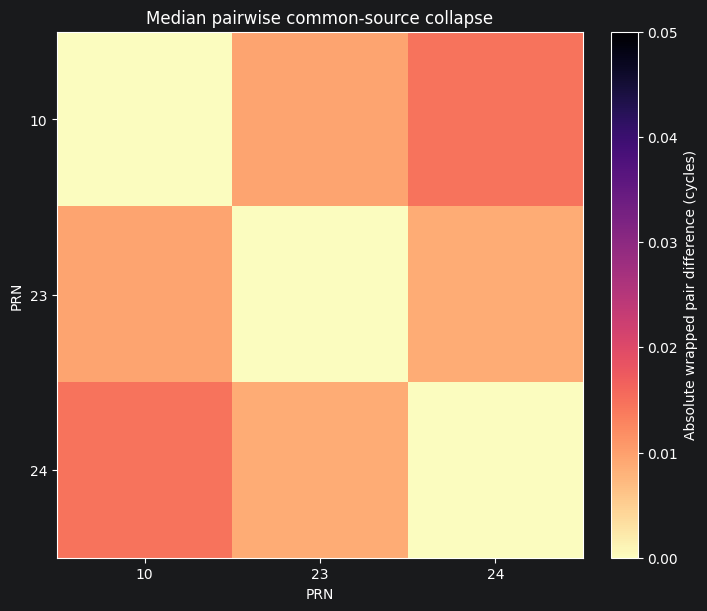

In [14]:
if not PARTIAL_SPOOF_ENABLED:
    tracked_svids = [
        svid for svid in SPOOF_SVIDS
        if svid in all_satellite_result.single_difference_cycles.columns
        and all_satellite_result.single_difference_cycles[svid].notna().any()
    ]
    single_difference = all_satellite_result.single_difference_cycles.reindex(
        columns=tracked_svids
    )

    pair_rows = []
    for left_index, left_svid in enumerate(tracked_svids):
        for right_svid in tracked_svids[left_index + 1:]:
            aligned = single_difference[[left_svid, right_svid]].dropna()
            residual = wrap_cycles(
                aligned[left_svid] - aligned[right_svid]
            ).abs()
            pair_rows.append(
                {
                    "left_svid": left_svid,
                    "right_svid": right_svid,
                    "epoch_count": len(residual),
                    "median_abs_wrapped_pair_cycles": residual.median(),
                    "p90_abs_wrapped_pair_cycles": residual.quantile(0.90),
                    "pct_epochs_le_0p03_cycles": 100 * residual.le(0.03).mean(),
                    "pct_epochs_le_0p05_cycles": 100 * residual.le(0.05).mean(),
                    "pct_epochs_le_0p10_cycles": 100 * residual.le(0.10).mean(),
                }
            )

    full_spoof_pairwise_summary = pd.DataFrame(pair_rows).sort_values(
        ["median_abs_wrapped_pair_cycles", "left_svid", "right_svid"]
    ).reset_index(drop=True)

    fractional_dd = all_satellite_result.fractional_dd_cycles.reindex(
        columns=tracked_svids
    )
    epoch_rows = []
    for epoch_index, row in fractional_dd.iterrows():
        values = row.dropna()
        pair_residuals = []
        for left_index, left_value in enumerate(values):
            for right_value in values.iloc[left_index + 1:]:
                pair_residuals.append(abs(wrap_cycles(left_value - right_value)))
        pair_residuals = np.asarray(pair_residuals, dtype=float)
        epoch_rows.append(
            {
                "epoch_index": epoch_index,
                "valid_satellite_count": len(values),
                "observed_pair_count": len(pair_residuals),
                "pair_fraction_le_0p03_cycles": (
                    np.mean(pair_residuals <= 0.03) if len(pair_residuals) else np.nan
                ),
                "pair_fraction_le_0p05_cycles": (
                    np.mean(pair_residuals <= 0.05) if len(pair_residuals) else np.nan
                ),
                "median_abs_wrapped_pair_cycles": (
                    np.median(pair_residuals) if len(pair_residuals) else np.nan
                ),
            }
        )

    full_spoof_epoch_summary = pd.DataFrame(epoch_rows)
    usable_epochs = full_spoof_epoch_summary[
        full_spoof_epoch_summary["observed_pair_count"].gt(0)
    ]
    full_spoof_common_source_summary = pd.DataFrame(
        [
            {
                "tracked_svids": tuple(tracked_svids),
                "satellite_pair_count": len(full_spoof_pairwise_summary),
                "synchronized_epoch_count": len(full_spoof_epoch_summary),
                "usable_epoch_count": len(usable_epochs),
                "zero_valid_phase_epoch_count": int(
                    full_spoof_epoch_summary["valid_satellite_count"].eq(0).sum()
                ),
                "mean_pairwise_median_abs_wrapped_cycles": (
                    full_spoof_pairwise_summary[
                        "median_abs_wrapped_pair_cycles"
                    ].mean()
                ),
                "max_pairwise_median_abs_wrapped_cycles": (
                    full_spoof_pairwise_summary[
                        "median_abs_wrapped_pair_cycles"
                    ].max()
                ),
                "mean_pair_observations_le_0p05_cycles_pct": (
                    full_spoof_pairwise_summary[
                        "pct_epochs_le_0p05_cycles"
                    ].mean()
                ),
                "pct_usable_epochs_at_least_half_pairs_le_0p05_cycles": (
                    100 * usable_epochs["pair_fraction_le_0p05_cycles"].ge(0.5).mean()
                ),
                "pct_usable_epochs_all_pairs_le_0p05_cycles": (
                    100 * usable_epochs["pair_fraction_le_0p05_cycles"].eq(1.0).mean()
                ),
                "reference_svid": result.reference_svid,
                "reference_alpha_deg": SCENARIO_CONFIG.alpha_r_deg,
                "reference_alpha_trust": "fixed experimental assumption; not independently surveyed",
            }
        ]
    )

    output_dir = SCENARIO_CONFIG.output_dir
    full_spoof_pairwise_summary.to_csv(
        output_dir / "paper_full_spoof_pairwise_common_source_collapse.csv",
        index=False,
    )
    full_spoof_epoch_summary.to_csv(
        output_dir / "paper_full_spoof_epoch_common_source_collapse.csv",
        index=False,
    )
    full_spoof_common_source_summary.to_csv(
        output_dir / "paper_full_spoof_common_source_summary.csv",
        index=False,
    )

    pair_matrix = pd.DataFrame(
        np.nan, index=tracked_svids, columns=tracked_svids, dtype=float
    )
    for svid in tracked_svids:
        pair_matrix.loc[svid, svid] = 0.0
    for pair in full_spoof_pairwise_summary.itertuples():
        pair_matrix.loc[pair.left_svid, pair.right_svid] = (
            pair.median_abs_wrapped_pair_cycles
        )
        pair_matrix.loc[pair.right_svid, pair.left_svid] = (
            pair.median_abs_wrapped_pair_cycles
        )

    fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
    image = ax.imshow(pair_matrix, vmin=0.0, vmax=0.05, cmap="magma_r")
    ax.set_xticks(range(len(tracked_svids)), tracked_svids)
    ax.set_yticks(range(len(tracked_svids)), tracked_svids)
    ax.set_xlabel("PRN")
    ax.set_ylabel("PRN")
    ax.set_title("Median pairwise common-source collapse")
    fig.colorbar(image, ax=ax, label="Absolute wrapped pair difference (cycles)")
    fig.savefig(
        output_dir / "paper_full_spoof_pairwise_common_source_collapse.png",
        dpi=180,
        bbox_inches="tight",
    )

    display(full_spoof_common_source_summary.round(4))
    display(full_spoof_pairwise_summary.round(4))
    display(fig)
    plt.close(fig)
else:
    print("Full-spoof common-source diagnostic is disabled for a partial-spoof scenario.")


In [15]:
required_outputs = [
    "paper_scenario_run_summary.csv",
    "paper_all_satellite_dd_method_aoa_deg.csv",
    "paper_all_satellite_fractional_dd_cycles.csv",
    "paper_all_satellite_ephemeris_aoa_rx1_deg.csv",
    "paper_all_satellite_ephemeris_aoa_rx2_deg.csv",
    "paper_all_satellite_valid_m_candidates.csv",
    "paper_all_satellite_valid_m_summary.csv",
    "paper_all_satellite_ephemeris_aligned_dd_method_aoa_deg.csv",
    "paper_all_satellite_ephemeris_aligned_branch.csv",
    "paper_all_satellite_dd_method_aoa_best_m_deg.csv",
    "paper_all_satellite_aoa_method_equivalence_summary.csv",
    "paper_receiver1_sv_used_all_epochs.csv",
    "paper_receiver2_sv_used_all_epochs.csv",
    "paper_sv_used_summary.csv",
    "paper_all_satellite_dd_method_aoa.png",
    "paper_all_satellite_fractional_dd.png",
    "paper_all_satellite_dd_method_aoa_best_m.png",
    "paper_best_m_dd_minus_ephemeris_deg.csv",
    "paper_best_m_dd_vs_ephemeris_error_summary.csv",
    "paper_best_m_dd_minus_ephemeris_by_satellite.png",
    "paper_best_m_dd_vs_ephemeris_absolute_error.png",
    "paper_all_satellite_ephemeris_aoa_rx1.png",
    "paper_all_satellite_ephemeris_aoa_rx2.png",
    "paper_all_satellite_valid_m_candidates.png",
    "paper_all_satellite_ephemeris_aligned_vs_ephemeris_aoa.png",
    "paper_sv_used_all_epochs_by_receiver.png",
    "hybrid_best_m_classification_scores.csv",
    "hybrid_best_m_residual_matrix_direction_cosine.csv",
    "hybrid_best_m_threshold_search.csv",
    "hybrid_best_m_pair_details.csv",
    "hybrid_best_m_satellite_consistency_details.csv",
    "hybrid_best_m_score_threshold_sensitivity.csv",
    "hybrid_best_m_pairwise_summary.csv",
    "hybrid_best_m_residual_heatmap_direction_cosine.png",
    "hybrid_best_m_common_direction_residuals_by_epoch.csv",
    "hybrid_best_m_common_direction_pairs.csv",
    "hybrid_best_m_common_direction_residual_matrix.csv",
    "hybrid_best_m_common_direction_matrix.csv",
    "hybrid_best_m_adjusted_pair_contribution_matrix.csv",
    "hybrid_best_m_adjusted_pair_details.csv",
    "hybrid_best_m_adjusted_classification_scores.csv",
    "hybrid_best_m_common_direction_group_report.csv",
    "hybrid_best_m_adjusted_classification_groups.csv",
    "hybrid_best_m_common_direction_summary.csv",
    "hybrid_best_m_adjusted_tau_q_outcome_bands.csv",
    "hybrid_best_m_common_direction_matrices.png",
]

if not PARTIAL_SPOOF_ENABLED:
    required_outputs = [
        name for name in required_outputs
        if not name.startswith("hybrid_best_m_")
    ]
    required_outputs.extend(
        [
            "paper_full_spoof_pairwise_common_source_collapse.csv",
            "paper_full_spoof_epoch_common_source_collapse.csv",
            "paper_full_spoof_common_source_summary.csv",
            "paper_full_spoof_pairwise_common_source_collapse.png",
        ]
    )

if PARTIAL_SPOOF_ENABLED:
    required_outputs.extend(
        [
            "paper_spoof_joint_source_aoa_deg.csv",
            "paper_spoof_joint_source_branch.csv",
            "paper_spoof_pairwise_convergence.csv",
            "paper_spoof_cluster_summary.csv",
            "paper_spoof_joint_source_dd_method_aoa.png",
        ]
    )

missing_outputs = [name for name in required_outputs if not (SCENARIO_CONFIG.output_dir / name).exists()]
assert not missing_outputs, f"Missing scenario outputs: {missing_outputs}"

assert len(result.epochs) > 0
assert result.reference_svid is not None
assert scenario.sv_used_rx1.shape[0] >= len(result.epochs)
assert scenario.sv_used_rx2.shape[0] >= len(result.epochs)

if PARTIAL_SPOOF_ENABLED:
    if HARDCODED_REFERENCE_SVID is None:
        assert result.reference_svid not in SPOOF_SVIDS
    else:
        assert result.reference_svid == HARDCODED_REFERENCE_SVID
    assert not scenario.joint_source_aoa_deg.empty
    assert not scenario.pairwise_convergence.empty
    assert set(SPOOF_SVIDS).issubset(set(scenario.sv_used_summary["svid"].astype(int)))
else:
    assert result.reference_svid == HARDCODED_REFERENCE_SVID
    assert set(SPOOF_SVIDS).issubset(
        set(scenario.all_satellite_dd_method_aoa_deg.columns.astype(int))
    )
    assert len(full_spoof_pairwise_summary) == len(SPOOF_SVIDS) * (len(SPOOF_SVIDS) - 1) // 2
    assert not full_spoof_common_source_summary.empty
    assert not full_spoof_fixed_m0_aoa_deg.empty
    assert set(full_spoof_fixed_m0_aoa_deg.columns.astype(int)) == set(SPOOF_SVIDS)

_validation_status = "ok"
print(f"Notebook validation: {_validation_status}; outputs: {SCENARIO_CONFIG.output_dir}")


AssertionError: 

## Notes

- The current configuration is the 2026-08-10 full-spoof closed-room capture.
- The approximately 82-degree DD-method AoA uses a fixed experimental PRN 6 anchor derived from spoof-affected Receiver 1 `NAV-SAT`; replace it with a surveyed angle before reporting the bearing.
- DD processing rejects carrier phases where u-blox reports unresolved half-cycle ambiguity (`halfCyc=0`).
- `full_spoof_fixed_m0_aoa_deg` is the best reconstruction under the known common-source hypothesis; the paper DP output is retained separately.
- Use the full-spoof pairwise fractional-DD tables as the primary common-source result.
- `svUsed` is full-log receiver behavior. It is intentionally independent of the selected DD-method AoA window.
